In [1]:
import numpy as np
import healpy as hp

import matplotlib
from matplotlib import pyplot as plt

from scipy import stats
import matplotlib.gridspec as gridspec
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from matplotlib import cm
from scipy.optimize import minimize
from astropy.cosmology import Planck18
from dynesty import NestedSampler
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc
from astropy.coordinates import SkyCoord
from healpy.newvisufunc import projview
from scipy import special
from scipy import linalg
from scipy.special import gamma

In [2]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# Model using step-function HOD
## Define parameters

In [3]:
G_hi = 20.5

In [4]:
nthreads = 18

In [5]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.6])
z_array = range(len(z_bins)-1)
mask = 0.5

In [6]:
cosmo_planck18 = ccl.Cosmology(Omega_c=0.265, Omega_b=Planck18.Ob0, h=Planck18.h, Neff = Planck18.Neff, T_CMB = Planck18.Tcmb0.value, m_nu = Planck18.m_nu, sigma8=0.8, n_s=0.95)

In [7]:
Delta = 200
delta_c = 1.686

In [8]:
hmf = ccl.halos.MassFuncTinker10()

In [9]:
NSIDE = 64

In [10]:
M_max = 15

## Define functions

In [11]:
def a_median(tab_datahi_mask_zbin0, key_zbin0 = ''):
    return 1/(1+np.median(tab_datahi_mask_zbin0['redshift_quaia'+key_zbin0]))

In [12]:
def b_qso(xi_qq, xi_mm, f):
    
    return np.sqrt(xi_qq/xi_mm-4*f**2/45)-f/3

In [13]:
def nu(M, delta_c = delta_c, a = 1, cosmo = cosmo_planck18):
    
    sigma = cosmo.sigmaM(M, a = a)
   
    return delta_c/sigma

In [14]:
def n_g_theory(bins, n_total, a = 1, cosmo = cosmo_planck18, hmf = hmf, recenter = True):
    """calculates the number density"""

    if recenter == True:
        bins = quaia.recenter(bins)
    nm = hmf(cosmo, bins, a)/cosmo['h']**3
    n_g = nm/(bins*np.log(10))*n_total
    n_g[np.isnan(n_g)]=0
    
    return n_g, nm

def bias(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True):
    """returns the bias and number density"""

    n_g, nm = n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter)
    if recenter == True:
        print('recentering')
        bins = quaia.recenter(bins)
    n_g = np.trapz(n_g, bins)
    dn_dm = nm/(bins*np.log(10))

    b1_E_tinker = b1_E_func(nu(bins, a = a, cosmo = cosmo), mod = mod)

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    return bias_function(n_g, integrand, b1_E_tinker, bins, recenter = recenter), n_g

In [15]:
def b1_E_func(nu, Delta = Delta, delta_c = delta_c, mod = False):
    """calculates the halo bias"""

    delta_c = 1.686
    
    if mod == False:
        y = np.log10(Delta)
        A =  1.0+0.24*y*np.exp(-(4/y)**4)
        a = 0.44*y-0.88
        B = 0.183
        b =  1.5
        C = 0.019+0.107*y+0.19*np.exp(-(4/y)**4)
        c = 2.4
        
    else:
        A =  1.0
        a = 0.0906
        B = -4.5002
        b =  2.1419
        C = 4.9148
        c = 2.1419
        
    return 1-A*nu**a/(nu**a+delta_c**a)+B*nu**b+C*nu**c # Jose et al
    
def bias_function(n_g, integrand, b, bins, recenter = True):
    """ integrates the bias"""
    
    if recenter == True:
        print('recentering')
        bins = quaia.recenter(bins)
        
    return 1/n_g*np.trapz(integrand*b, bins)

In [16]:
def cf_2h(bins, n_m, a, cosmo, cf_matter, recenter = True):
    """implements the 2halo term"""
    
    b_q, n_g = bias(bins, n_m, a, cosmo, recenter = recenter)
    return b_q**2*cf_matter, b_q

In [17]:
def M(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True, hmf = hmf):

    n_g, nm = n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter, hmf = hmf)
    if recenter == True:
        n_g = np.trapz(n_g, quaia.recenter(bins))
        dm = np.diff(bins) 
        dn_dm = nm/(quaia.recenter(bins)*np.log(10))
    else:
        n_g = np.trapz(n_g, bins)
        dn_dm = nm/(bins*np.log(10))

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    if recenter == True:
        return bias_function(n_g, integrand, quaia.recenter(bins), bins, recenter = recenter), n_g
    else:
        return bias_function(n_g, integrand, bins, bins, recenter = recenter), n_g

In [18]:
def HOD(bins, M_min, fduty):

    n_m=np.zeros(np.shape(quaia.recenter(bins)))
    n_m[quaia.recenter(bins)>=M_min]=fduty

    return n_m

In [19]:
def n_DM(cosmo, a, M_min, hmf = hmf, M_max = M_max, N = 79): #16.8
    
    bins = np.logspace(M_min, M_max, N)
    nm = hmf(cosmo, bins, a)/cosmo['h']**3 #/u.Mpc**3 # convert to h/Mpc**3
    dn_dm = nm/(bins*np.log(10))
    
    return np.trapz(dn_dm, bins)

# Implement halo model
## Plot HOD: $\langle N\left(M\right)\rangle=\frac{f_{\text {duty }}}{2} \operatorname{erfc}\left[\frac{\ln (M_\mathrm{min} / M)}{\sqrt{2} \log{10} \Sigma}\right]$
### At fixed $f_{duty}$ and $M_{min}$

In [20]:
n_bins = 79 #159

In [21]:
bins = np.logspace(9, M_max, n_bins)

In [22]:
M_min_array_old = [12.86, 12.74, 12.79, 12.82]
M_min_array = [11.94, 11.98, 11.97, 12.07]

In [23]:
fduty_old = [0.018, 0.022, 0.056, 0.071]
fduty = [0.002, 0.002, 0.003, 0.002]

def HOD_scatter(fduty, M_min, M, sigma):
    
    return fduty/2*special.erfc(np.log(10**M_min/M)/(np.sqrt(2)*np.log(10)*sigma))

In [24]:
cmap_blue = plt.get_cmap('Blues')(np.linspace(0.333, 0.999, len(z_array)))

<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\S'
<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_172415/2586165201.py:15: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(bins_i, n_m, linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1), color = cmap_blue[i])
/tmp/ipykernel_172415/2586165201.py:24: SyntaxWarning: invalid escape sequence '\o'
  ax1.set_xlabel('$M (M_\odot)$')
/tmp/ipykernel_172415/2586165201.py:31: SyntaxWarning: invalid escape sequence '\S'
  ax1.set_title('$\Sigma={}$ dex'.format(sigma_array[j]))
/tmp/ipykernel_172415/480457471.py:6: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/M)/(np.sqrt(2)*np.log(10)*sigma))
/tmp/ipykernel_172415/480457471.py:6: RuntimeWarning: invalid value

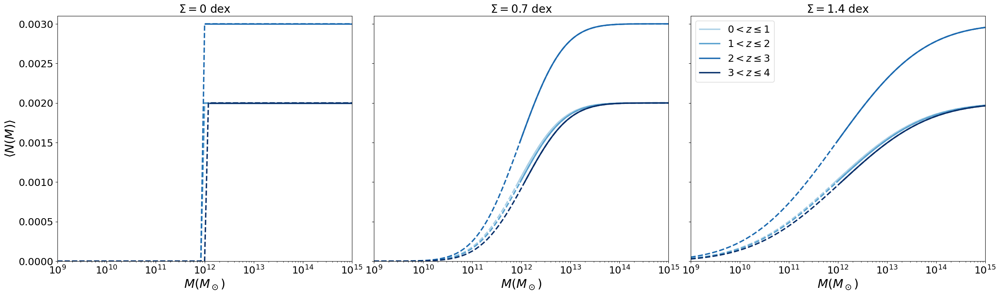

In [25]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.075)
sigma_array = [0, 0.7, 1.4]
n_m_array, bins_M_min = [], []

for j in range(len(sigma_array)):
    
    ax1 = fig.add_subplot(gs[j])
        
    for i in z_array:
        
        bins_i = np.logspace(M_min_array[i], M_max, n_bins)

        n_m = HOD_scatter(fduty[i], M_min_array[i], bins_i, sigma_array[j])
        ax1.plot(bins_i, n_m, linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1), color = cmap_blue[i])
        ax1.plot(bins, HOD_scatter(fduty[i], M_min_array[i], bins, sigma_array[j]), linewidth = 2.5, linestyle ='--', color = cmap_blue[i])

        if j == 0:
            
            n_m_array.append(n_m)
            bins_M_min.append(bins_i)
    
    ax1.set_xscale('log')
    ax1.set_xlabel('$M (M_\odot)$')
    
    if j== 0:
        ax1.set_ylabel(r'$\langle N(M) \rangle$')
    else:
        ax1.set_yticklabels([])
    
    ax1.set_title('$\Sigma={}$ dex'.format(sigma_array[j]))
    ax1.set_xlim(1e9,10**M_max)
    ax1.set_ylim(0, 0.0031)
    
    print()
    
ax1.legend()
plt.show()

## Calculate $b_{\mathrm{qq}}(s,z)=\sqrt{\frac{\xi^{(s)}_{\mathrm{qq}}(s)}{\xi^{(r)}_\mathrm{mm}(r)}-\frac{4 \Omega_{\mathrm{m}}^{1.2}(z)}{45}}-\frac{\Omega_{\mathrm{m}}^{0.6}(z)}{3}$
### Use a 50th percentile mask

In [26]:
bins_M_min_array = [np.logspace(np.log10(bins[j]), M_max, n_bins) for j in range(len(bins))]

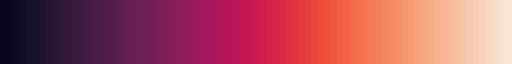

In [27]:
cmap = sns.color_palette("rocket", n_colors = len(bins))
palette = matplotlib.colors.ListedColormap(cmap)
palette

# Calculate derived parameters
## Plot b(z)

In [28]:
def b_eboss(z):
    
    return 0.278*((1+z)**2-6.565) + 2.393

def b_quaia(b_0, a, cosmo = cosmo_planck18): #quaia):
    
    return b_0/ccl.growth_factor(cosmo, a)

In [29]:
b_cf20 = np.load('../results/b_cf20_planck18.npy')
b_wp20 = np.load('../results/b_wp20_planck18.npy')

# Calculate number density as $n_q \approx \int_0^{\infty} d M \frac{d n}{d M}\langle N(M)\rangle$

In [30]:
tab_datahi_mask_zbins, selfunc_hi_bins = [], []
for j in z_array:
    
    tab_datahi_mask_zbin0, _, _, _, _, _, selfunc_hi_bin0, _, pixel_indices_datahi_bin0 = quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask*100, percentile = True)
    tab_datahi_mask_zbins.append(tab_datahi_mask_zbin0['redshift_quaia'])
    selfunc_hi_bins.append(selfunc_hi_bin0)

0.6894778799187598
Pixels masked by MC but not already by selfunc: 1911
G20.5_zmin0.0zmax1.0: 0.31              224099 vs 324336
0.6998052038245415
Pixels masked by MC but not already by selfunc: 3700
G20.5_zmin1.0zmax2.0: 0.28              464321 vs 648196
0.7010382664423291
Pixels masked by MC but not already by selfunc: 3094
G20.5_zmin2.0zmax3.0: 0.25              214535 vs 286508
0.7686898940836221
Pixels masked by MC but not already by selfunc: 352
G20.5_zmin3.0zmax4.6: 0.22              28576 vs 36458


In [31]:
LMC = SkyCoord(['05 23 34.6 -69 45 22'], unit=(u.hourangle, u.deg)) #https://simbad.u-strasbg.fr/simbad/sim-id?Ident=Large+Magellanic+Cloud

In [32]:
LMC_radius = 9*u.deg

In [33]:
SMC = SkyCoord(['00 52 38.0 -72 48 01'], unit=(u.hourangle, u.deg)) # https://simbad.u-strasbg.fr/simbad/sim-id?Ident=small+Magellanic+Cloud

In [34]:
SMC_radius = 5*u.deg

In [35]:
n_q, n_q_err, V_eff, N_q = [], [], [], []

for j in z_array:
    
    N = len(tab_datahi_mask_zbins[j])
    theta, phi = hp.pix2ang(NSIDE, range(len(selfunc_hi_bins[j])), lonlat=True)
    c = SkyCoord(ra=theta*u.degree, dec=phi*u.degree)
    LMC_idx, _, _, _ = SkyCoord.search_around_sky(LMC, c, LMC_radius)
    SMC_idx, _, _, _ = SkyCoord.search_around_sky(SMC, c, SMC_radius)
    MC_idx = np.append(LMC_idx,SMC_idx)
    MC_mask = np.full_like(range(len(selfunc_hi_bins[j])), True, dtype = bool)
    MC_mask[MC_idx] = False
    cp = np.percentile(selfunc_hi_bins[j][MC_mask], mask*100)
    selfunc_mask = selfunc_hi_bins[j]>=cp
    f_sky = 1/(4*np.pi)*np.sum(selfunc_hi_bins[j][selfunc_mask & MC_mask]*hp.nside2pixarea(NSIDE))
    print(f_sky) # f_sky)
    V = f_sky*(Planck18.comoving_volume(z_bins[j+1])-Planck18.comoving_volume(z_bins[j]))*Planck18.h**3/u.h**3
    N_q.append(N)
    n_q.append(N/V.value)
    n_q_err.append(np.sqrt(N)/V.value) # Poisson error
    V_eff.append(V)
    
n_q

0.3815553400077859
0.3990266387789277
0.42567567827451197
0.43715916212910605


[1.1562053955390066e-05,
 8.122737301033735e-06,
 3.0936220453800634e-06,
 2.72364137384074e-07]

## Limit scales to $30\geq s \geq 80h^{-1}$ Mpc

In [36]:
# Create the bins array
rmin = 30 #30-delta_min*offset # 0.1 # start higher # 1.4 # 30
rmax = 80 #80+delta_max*offset # 200
nbins = 10 #int((rmax-rmin)/offset) #20 + int(delta_min+delta_max) #90 #20
rbins_chi2 = np.linspace(rmin, rmax, nbins + 1) # Mpc/h https://github.com/manodeep/Corrfunc/issues/202
scale = 'linear'
rbins_chi2, quaia.recenter(rbins_chi2), np.diff(quaia.recenter(rbins_chi2))

(array([30., 35., 40., 45., 50., 55., 60., 65., 70., 75., 80.]),
 array([32.5, 37.5, 42.5, 47.5, 52.5, 57.5, 62.5, 67.5, 72.5, 77.5]),
 array([5., 5., 5., 5., 5., 5., 5., 5., 5.]))

In [37]:
pimax = 80 # 40 # 5000.0 # 40.0\

In [38]:
dpi = 0.01
pibins = np.arange(0, pimax+1, dpi)

In [39]:
wp_chi2, wp_matter_chi2, rpavg_chi2 = [], [], []
b_wp_chi2 = []
a_zbin, b_wp_q = [], []
rpmask = []
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask*100, percentile = True)

    # quasar correlation function
    wp_zbin_i, rpavg_zbin_i = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, nthreads = nthreads, 
                                                                  rbins = rbins_chi2, nbins = nbins, pimax = pimax, Om0 = Planck18.Om0, h = Planck18.h)
    wp_chi2.append(wp_zbin_i)
    rpavg_chi2.append(rpavg_zbin_i)

    # scale factor
    a = a_median(tab_datahi_mask_zbin0)
    a_zbin.append(a)

    # matter correlation function   
    s = np.sqrt(np.sum(np.meshgrid(np.array(rpavg_zbin_i)**2, quaia.recenter(pibins)**2), axis = 0))
    s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(H0))
        
    xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo_planck18, r=np.ravel(s_Mpc), a=a_median(tab_datahi_mask_zbin0))
    wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
    wp_matter_chi2.append(wp_matter_zbin_i)        

    # effective bias 
    b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)
    b_wp_chi2.append(b)

    # qso bias
    b_wp_q.append(b_qso(wp_zbin_i, wp_matter_zbin_i, ccl.growth_rate(cosmo_planck18, a)))
    
    rpmask.append((np.array(rpavg_zbin_i) >= 30) & (np.array(rpavg_zbin_i) <= 80))

0.6894778799187598
Pixels masked by MC but not already by selfunc: 1911
G20.5_zmin0.0zmax1.0: 0.31              224099 vs 324336


[Warning] The CPU supports AVX512F but the compiler does not.  Can you try another compiler?
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.6998052038245415
Pixels masked by MC but not already by selfunc: 3700
G20.5_zmin1.0zmax2.0: 0.28              464321 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_172415/1960285231.py:33: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)
/tmp/ipykernel_172415/4043121211.py:3: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(xi_qq/xi_mm-4*f**2/45)-f/3


0.7010382664423291
Pixels masked by MC but not already by selfunc: 3094
G20.5_zmin2.0zmax3.0: 0.25              214535 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_172415/1960285231.py:33: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)
/tmp/ipykernel_172415/4043121211.py:3: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(xi_qq/xi_mm-4*f**2/45)-f/3


0.7686898940836221
Pixels masked by MC but not already by selfunc: 352
G20.5_zmin3.0zmax4.6: 0.22              28576 vs 36458


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/tmp/ipykernel_172415/1960285231.py:33: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(wp_zbin_i/wp_matter_zbin_i)
/tmp/ipykernel_172415/4043121211.py:3: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(xi_qq/xi_mm-4*f**2/45)-f/3


## Compute the maximum number of jackknife regions

In [40]:
N_j = 50

In [41]:
for j in z_array:
    
    # calculating N_jk first
    s_min = Planck18.comoving_transverse_distance(1/a_zbin[j]-1)*2*np.pi*Planck18.h/u.h
    N_jk_max = np.floor(s_min/(5*rmax*s_min.unit))
    theta_min = np.ceil(360/N_jk_max)
    
    # calculating theta first
    # s_min = Planck18.comoving_distance(1/a_zbin[j]-1)*Planck18.h/u.h
    # theta_min = np.ceil(np.rad2deg(rmax*s_min.unit/s_min*u.rad))
    # N_jk_max = np.floor(360*u.deg/theta_min)

    print('N_j_max:', N_jk_max)
    print('N_q:', int(N_q[j]/N_j))
    print('theta_min:', theta_min)
    print()
    
print('hartlap:', (N_j-nbins-2)/(N_j-1))
print('dodelson:', 1+nbins/N_j)

N_j_max: 28.0
N_q: 4481
theta_min: 13.0

N_j_max: 47.0
N_q: 9286
theta_min: 8.0

N_j_max: 61.0
N_q: 4290
theta_min: 6.0

N_j_max: 71.0
N_q: 571
theta_min: 6.0

hartlap: 0.7755102040816326
dodelson: 1.2


# Perform nested sampling with dynesty

In [42]:
# Define the dimensionality of our problem.
ndim = 3

## Pick cosmology

In [43]:
cosmo = 'Planck'

In [44]:
N = 50 #20 #65 # 50 #30 #15 #45 #85

In [45]:
def wp_2h(bins, n_m, a, cosmo, wp_matter_zbin_i, rpbins = rbins_chi2, pibins = pibins, recenter = True, rpmask = True):

    if not isinstance(wp_matter_zbin_i, np.ndarray):
        
        print('computing wp_matter')
        
        # matter correlation function    
        if isinstance(rpmask, bool):
            rpmask = [rpmask]*len(quaia.recenter(rpbins))
            
        s = np.sqrt(np.sum(np.meshgrid(quaia.recenter(rpbins)[rpmask]**2, quaia.recenter(pibins)**2), axis = 0))
        s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(cosmo['h']* 100 * u.km/u.s/u.Mpc))

        xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo, r=np.ravel(s_Mpc), a=a)
        wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)

    return cf_2h(bins, n_m, a, cosmo, wp_matter_zbin_i, recenter = recenter)

In [46]:
# Define our 3-D correlated multivariate normal log-likelihood.
C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_Planck_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N)) 
ix_grid = np.ix_(rpmask[j], rpmask[j])
hartlap = (N-nbins-2)/(N-1)
print(hartlap)

# check if cov is hermitian and positive definite
if linalg.ishermitian(C) and np.all(np.linalg.eigvals(C) > 0):
    C_factor = linalg.cho_factor(C[ix_grid])
    log_det_C = 2 * np.sum(np.log(np.diag(C_factor[0])))
    solve = lambda rhs: linalg.cho_solve(C_factor, rhs)
else:
    print('using LU decomposition')
    C_factor = linalg.lu_factor(C[ix_grid])
    log_det_C = np.sum(np.log(np.abs(np.diag(C_factor[0])))) # does abs value make sense
    solve = lambda rhs: linalg.lu_solve(C_factor, rhs)
    
def loglike(x, a, wp_matter, log_det_C, wp, n_q, nbins, rpbins = rbins_chi2, pibins = pibins, cosmo = cosmo_planck18, error = 0.05, M_max = M_max, bins = bins, hartlap = hartlap, solve = solve, N = N):
    
    fduty, M_min, sigma = x
    n_m=HOD_scatter(10**fduty, M_min, bins, sigma)
        
    n_q_theory = M(bins, n_m, a = a, cosmo = cosmo, recenter = False)[1]
    # penalty = np.abs(n_q_theory-n_q)/n_q
    # if penalty > error:
    #     return -np.inf
    #     # return -1e300
    penalty = 0.5*((n_q_theory-n_q)/(error*n_q))**2
        
    wp_2h_zbin, _ = wp_2h(bins, n_m, a, cosmo, wp_matter, rpbins=rpbins, pibins=pibins, recenter = False)
    delta = wp-wp_2h_zbin
    
    c_p = gamma(N/2)/((np.pi*(N-1))**(nbins/2)*gamma((N-nbins)/2))
    lnorm = np.log(c_p)-0.5*log_det_C  
    
    return -N*0.5 * np.log(1+(delta.T @ solve(delta))/(N-1)) + lnorm - penalty

0.7755102040816326


In [47]:
def ptform(u):
    """Transforms the uniform random variables `u ~ Unif[0., 1.)`
    to the parameters of interest."""

    x = np.array(u)  # copy u 

    # Uniform from -6 to 0
    x[0] = 6* u[0] - 6 # scale and shift to [-6., 0.)

    # Uniform from 9 to 15
    x[1] = 6 * u[1] + 9  # scale and shift to [9., 15.)
    
    # Uniform from 0 to 1.4
    x[2] = 1.4 * u[2]  # scale to [0., 1.4.)

    return x

In [48]:
nlive = 3000
dlogz = 0.001

In [49]:
# initialize our nested sampler
sampler = NestedSampler(loglike, ptform, ndim, logl_args=[a_zbin[j], wp_matter_chi2[j][rpmask[j]], log_det_C, wp_chi2[j][rpmask[j]], n_q[j], nbins], nlive = nlive)

In [50]:
# run the sampler with checkpointing
sampler.run_nested(dlogz = dlogz)
results = sampler.results

35728it [07:01, 127.03it/s, bound: 91 | nc: 7 | ncall: 382671 | eff(%):  9.336 | loglstar:   -inf < -29.939 <    inf | logz: -35.365 +/-  0.035 | dlogz:  0.002 >  0.001]        /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
36550it [07:20, 121.09it/s, bound: 96 | nc: 7 | ncall: 398648 | eff(%):  9.168 | loglstar:   -inf < -29.938 <    inf | logz: -35.365 +/-  0.035 | dlogz:  0.001 >  0.001]  /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined 

In [51]:
# Print out a summary of the results.
results.summary()

Summary
nlive: 3000
niter: 37013
ncall: 414801
eff(%):  9.646
logz: -35.364 +/-  0.040


<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:3: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_172415/2088523137.py:3: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)


Text(0.5, 0.9, '$3.0<z \\leq4.6$')

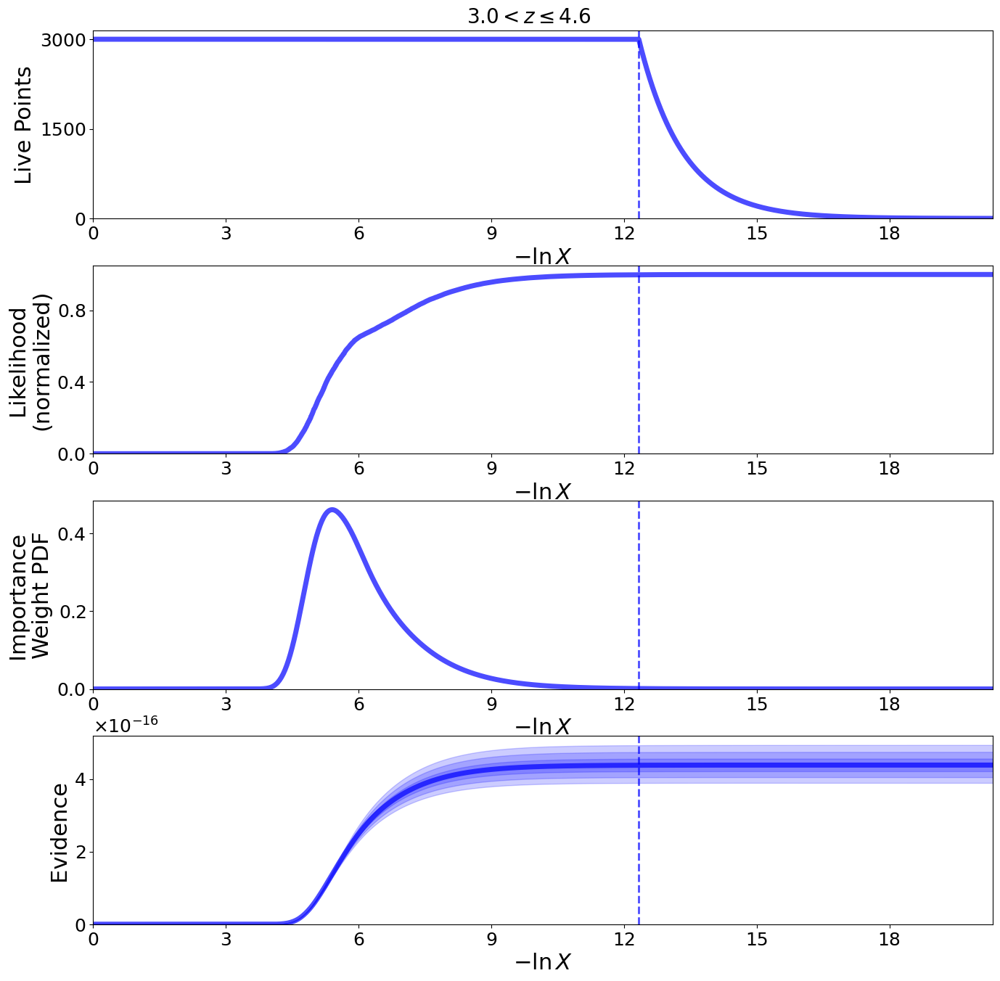

In [52]:
fig, axes = dyplot.runplot(results)  # summary (run) plot
fig.subplots_adjust(hspace=0.25)
fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)

<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_172415/1024485889.py:6: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.95)


Text(0.5, 0.95, '$3.0<z \\leq4.6$')

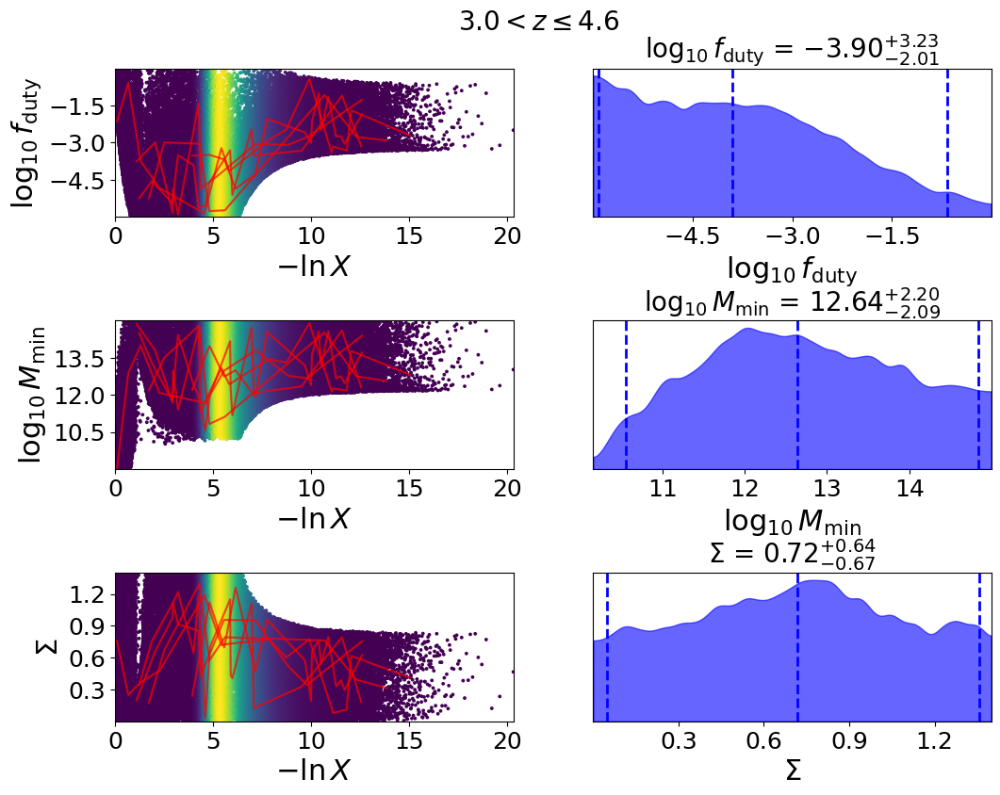

In [53]:
fig, axes = dyplot.traceplot(results, 
                             show_titles=True,
                             trace_cmap='viridis', connect=True,
                             connect_highlight=range(5), labels=[r'$\log_{10}f_\mathrm{duty}$', r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$'])
fig.subplots_adjust(hspace=0.7)
fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.95)

<>:7: SyntaxWarning: invalid escape sequence '\l'
<>:7: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_172415/4225580685.py:7: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.375)


Text(0.375, 0.975, '$3.0<z \\leq4.6$')

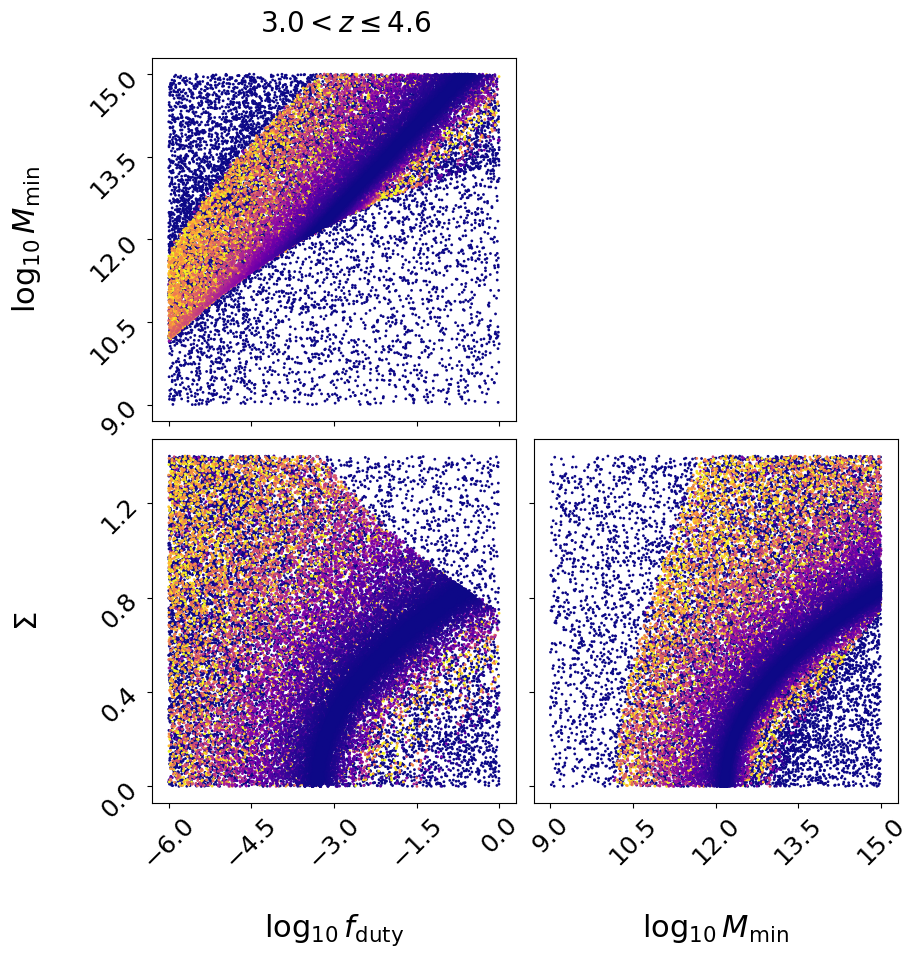

In [54]:
# initialize figure
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# plot initial run (res1; left)
fg, ax = dyplot.cornerpoints(results, cmap='plasma',
                             kde=False, labels=[r'$\log_{10}f_\mathrm{duty}$', r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$'], fig=(fig, axes))
fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.375)

<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_172415/2194410425.py:8: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 1, x = 0.25)


Text(0.25, 1, '$3.0<z \\leq4.6$')

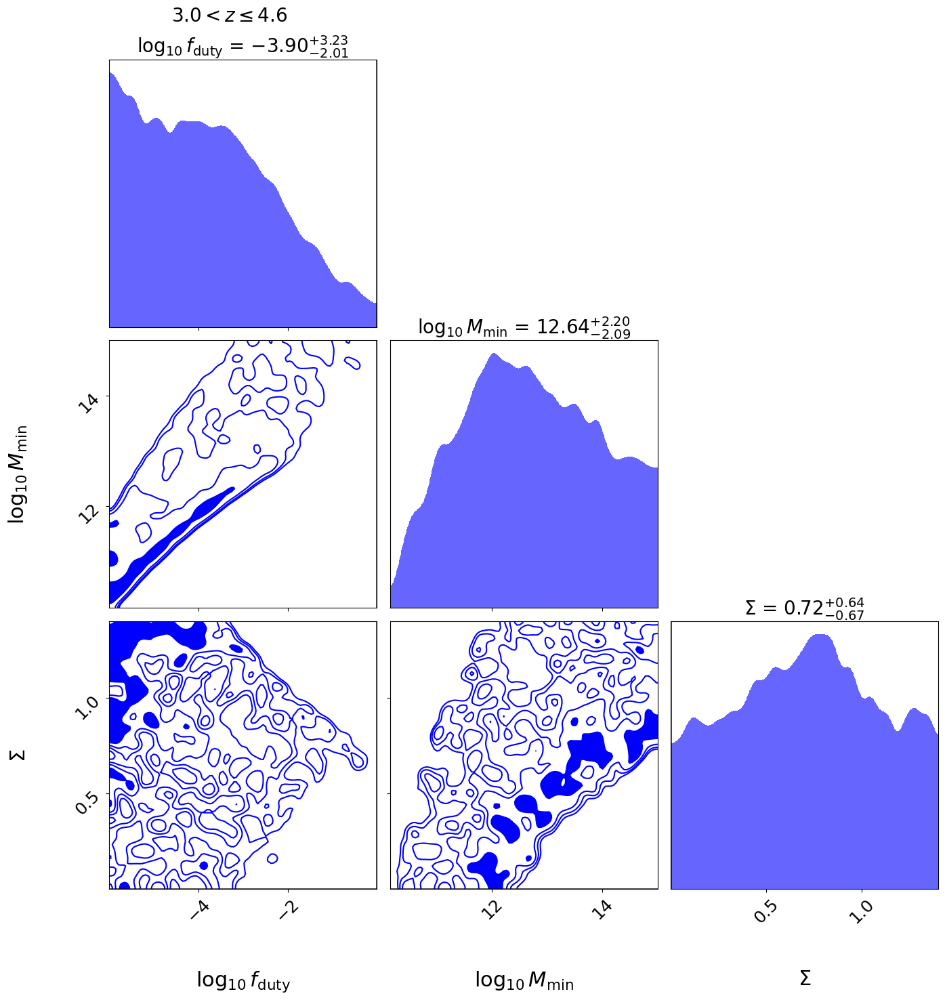

In [55]:
# # initialize figure
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

# plot initial run (res1; left)
fg, ax = dyplot.cornerplot(results, color='blue', truths=np.zeros(ndim),
                           truth_color='black', show_titles=True,
                           max_n_ticks=3, quantiles=None, labels=[r'$\log_{10}f_\mathrm{duty}$', r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$'], fig=(fig, axes[:, :3]))
fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 1, x = 0.25)

<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_172415/608613858.py:2: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('$N_\mathrm{iter}$')
/tmp/ipykernel_172415/608613858.py:3: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log(z) uncertainty$')


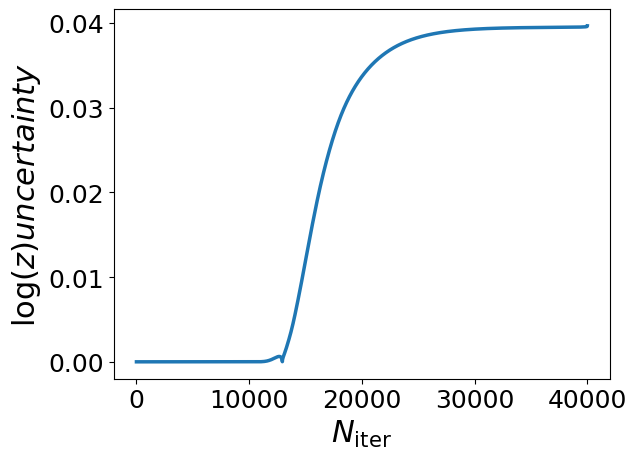

In [56]:
plt.plot(results.logzerr, linewidth = 2.5)
plt.xlabel('$N_\mathrm{iter}$')
plt.ylabel('$\log(z) uncertainty$')
plt.show()

In [57]:
samples, weights = results.samples, results.importance_weights()
mean, cov = dyfunc.mean_and_cov(samples, weights)
print(mean, cov)

[-3.77079921 12.69447571  0.70789825] [[ 2.13503279  1.39965689 -0.05704285]
 [ 1.39965689  1.44521872  0.21960515]
 [-0.05704285  0.21960515  0.14338343]]


In [58]:
# Compute weighted quantiles
samples, weights = results.samples, results.importance_weights()

# Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
quantiles = [dyfunc.quantile(samples[:, i], [0.025, 0.5, 0.975], weights=weights) 
             for i in range(samples.shape[1])]
labels = ['log10(f_duty)', 'log10(M_min)', 'sigma']

for i, (lo, mid, hi) in enumerate(quantiles):
    print(f"{labels[i]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}")

log10(f_duty): -3.90 + 3.23/-2.01
log10(M_min): 12.64 + 2.20/-2.09
sigma: 0.72 + 0.64/-0.67


In [59]:
weights = np.exp(results.logwt - results.logz[-1])
ESS = 1.0 / np.sum(weights**2)
print(f"Effective samples: {ESS:.0f}")
# You want this >> 100, ideally 1000+

Effective samples: 9878


## Convergence criterion

<>:50: SyntaxWarning: invalid escape sequence '\s'
<>:51: SyntaxWarning: invalid escape sequence '\l'
<>:50: SyntaxWarning: invalid escape sequence '\s'
<>:51: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_205030/438503005.py:50: SyntaxWarning: invalid escape sequence '\s'
  plt.fill_between(range(len(seeds)), mean-std, mean+std, alpha = 0.5, label = '$1\sigma')
/tmp/ipykernel_205030/438503005.py:51: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log(z)$')


0.0<z<=1.0


43019it [02:42, 264.01it/s, +3000 | bound: 47 | nc: 1 | ncall: 248968 | eff(%): 18.709 | loglstar:   -inf < -6.336 <    inf | logz: -13.764 +/-  0.046 | dlogz:  0.000 >  0.001]  


seed=421: logZ = -13.764 ± 0.046


43133it [02:44, 262.83it/s, +3000 | bound: 48 | nc: 1 | ncall: 251466 | eff(%): 18.567 | loglstar:   -inf < -6.336 <    inf | logz: -13.802 +/-  0.046 | dlogz:  0.000 >  0.001]  


seed=426: logZ = -13.802 ± 0.046


43064it [02:46, 258.18it/s, +3000 | bound: 48 | nc: 1 | ncall: 254010 | eff(%): 18.351 | loglstar:   -inf < -6.336 <    inf | logz: -13.780 +/-  0.046 | dlogz:  0.000 >  0.001]  


seed=175: logZ = -13.780 ± 0.046


43135it [02:50, 253.55it/s, +3000 | bound: 48 | nc: 1 | ncall: 254527 | eff(%): 18.342 | loglstar:   -inf < -6.336 <    inf | logz: -13.803 +/-  0.046 | dlogz:  0.000 >  0.001]  


seed=949: logZ = -13.803 ± 0.046


43052it [03:35, 200.03it/s, +3000 | bound: 62 | nc: 1 | ncall: 295854 | eff(%): 15.725 | loglstar:   -inf < -6.336 <    inf | logz: -13.776 +/-  0.046 | dlogz:  0.000 >  0.001]  


seed=986: logZ = -13.776 ± 0.046

Mean logZ: -13.785
Std logZ:  0.015


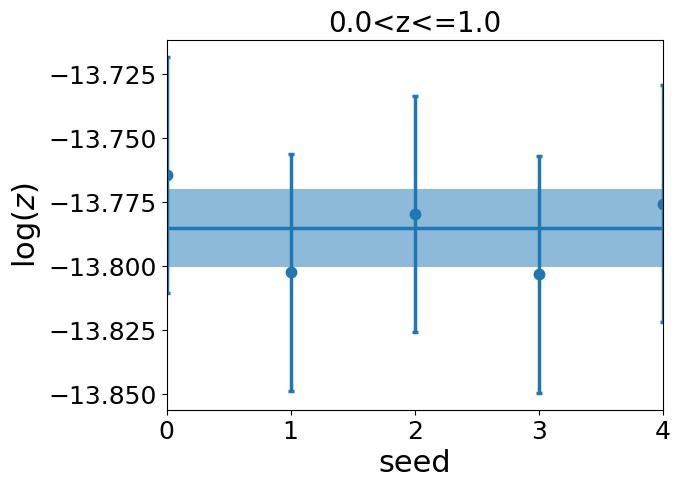

1.0<z<=2.0


42627it [02:56, 242.15it/s, +3000 | bound: 46 | nc: 1 | ncall: 248333 | eff(%): 18.598 | loglstar:   -inf < -1.327 <    inf | logz: -8.625 +/-  0.045 | dlogz:  0.000 >  0.001]  


seed=421: logZ = -8.625 ± 0.046


42707it [02:55, 243.01it/s, +3000 | bound: 48 | nc: 1 | ncall: 253474 | eff(%): 18.248 | loglstar:   -inf < -1.327 <    inf | logz: -8.652 +/-  0.046 | dlogz:  0.000 >  0.001]   


seed=426: logZ = -8.652 ± 0.046


42560it [02:40, 265.51it/s, +3000 | bound: 43 | nc: 1 | ncall: 238306 | eff(%): 19.362 | loglstar:   -inf < -1.327 <    inf | logz: -8.603 +/-  0.046 | dlogz:  0.000 >  0.001]   


seed=175: logZ = -8.603 ± 0.046


42728it [02:48, 254.23it/s, +3000 | bound: 46 | nc: 1 | ncall: 246805 | eff(%): 18.756 | loglstar:   -inf < -1.327 <    inf | logz: -8.659 +/-  0.046 | dlogz:  0.000 >  0.001]   


seed=949: logZ = -8.659 ± 0.046


42771it [02:48, 253.79it/s, +3000 | bound: 47 | nc: 1 | ncall: 250436 | eff(%): 18.498 | loglstar:   -inf < -1.327 <    inf | logz: -8.673 +/-  0.046 | dlogz:  0.000 >  0.001]   


seed=986: logZ = -8.673 ± 0.046

Mean logZ: -8.643
Std logZ:  0.025


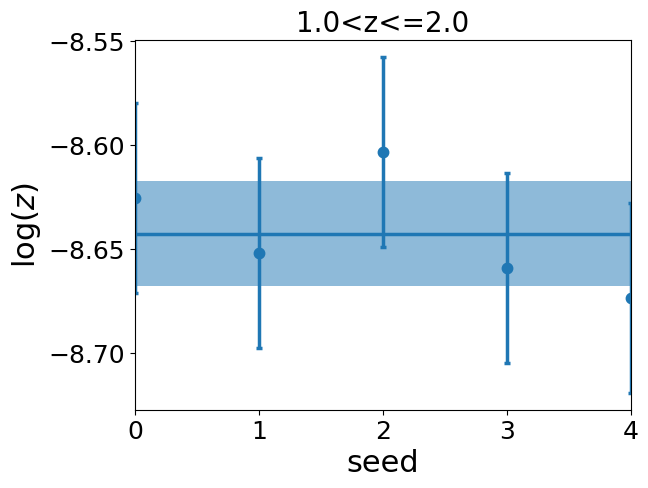

2.0<z<=3.0


42796it [03:36, 197.43it/s, +3000 | bound: 66 | nc: 1 | ncall: 305620 | eff(%): 15.133 | loglstar:   -inf < -13.358 <    inf | logz: -20.712 +/-  0.046 | dlogz:  0.000 >  0.001] 


seed=421: logZ = -20.712 ± 0.046


42770it [03:14, 219.93it/s, +3000 | bound: 56 | nc: 1 | ncall: 276910 | eff(%): 16.710 | loglstar:   -inf < -13.358 <    inf | logz: -20.704 +/-  0.046 | dlogz:  0.000 >  0.001] 


seed=426: logZ = -20.704 ± 0.046


42260it [03:30, 179.03it/s, bound: 63 | nc: 18 | ncall: 297359 | eff(%): 14.212 | loglstar:   -inf < -13.359 <    inf | logz: -20.759 +/-  0.046 | dlogz:  0.001 >  0.001]        /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
42646it [03:35, 188.68it/s, bound: 65 | nc: 6 | ncall: 303340 | eff(%): 14.059 | loglstar:   -inf < -13.359 <    inf | logz: -20.759 +/-  0.046 | dlogz:  0.001 >  0.001] /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined 

seed=175: logZ = -20.758 ± 0.046


43053it [03:32, 203.00it/s, +3000 | bound: 64 | nc: 1 | ncall: 300663 | eff(%): 15.472 | loglstar:   -inf < -13.358 <    inf | logz: -20.798 +/-  0.046 | dlogz:  0.000 >  0.001] 


seed=949: logZ = -20.798 ± 0.046


42888it [03:31, 33.15it/s, bound: 62 | nc: 13 | ncall: 294538 | eff(%): 14.561 | loglstar:   -inf < -13.359 <    inf | logz: -20.804 +/-  0.046 | dlogz:  0.001 >  0.001]         /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
43067it [03:36, 198.96it/s, +3000 | bound: 64 | nc: 1 | ncall: 302008 | eff(%): 15.407 | loglstar:   -inf < -13.358 <    inf | logz: -20.803 +/-  0.046 | dlogz:  0.000 >  0.001]


seed=986: logZ = -20.803 ± 0.046

Mean logZ: -20.755
Std logZ:  0.041


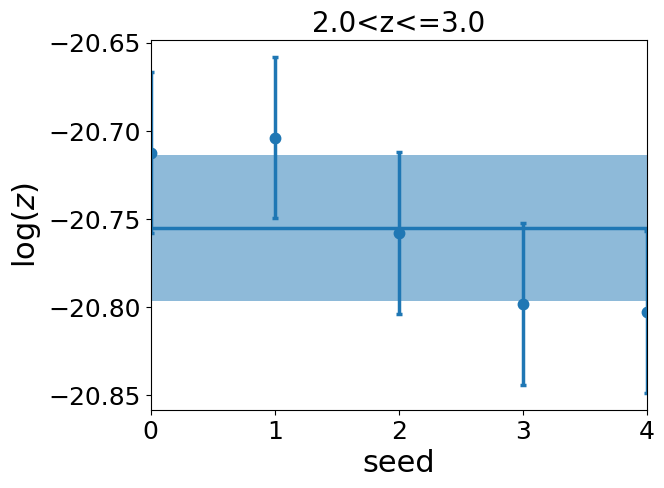

3.0<z<=4.6


36310it [04:25, 60.17it/s, bound: 82 | nc: 38 | ncall: 355925 | eff(%): 10.202 | loglstar:   -inf < -29.939 <    inf | logz: -35.424 +/-  0.044 | dlogz:  0.001 >  0.001]         /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
37077it [04:44, 86.03it/s, bound: 89 | nc: 30 | ncall: 379188 | eff(%):  9.778 | loglstar:   -inf < -29.938 <    inf | logz: -35.423 +/-  0.044 | dlogz:  0.001 >  0.001]  /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined

seed=421: logZ = -35.422 ± 0.040


37066it [04:37, 133.39it/s, +3000 | bound: 89 | nc: 1 | ncall: 375795 | eff(%): 10.747 | loglstar:   -inf < -29.937 <    inf | logz: -35.381 +/-  0.047 | dlogz:  0.000 >  0.001] 


seed=426: logZ = -35.381 ± 0.040


36607it [05:08, 12.61it/s, bound: 101 | nc: 82 | ncall: 414054 | eff(%):  8.841 | loglstar:   -inf < -29.938 <    inf | logz: -35.383 +/-  0.042 | dlogz:  0.001 >  0.001]        /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
36645it [05:13,  6.74it/s, bound: 103 | nc: 444 | ncall: 420625 | eff(%):  8.712 | loglstar:   -inf < -29.938 <    inf | logz: -35.383 +/-  0.042 | dlogz:  0.001 >  0.001]/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined

seed=175: logZ = -35.382 ± 0.040


37070it [04:10, 147.90it/s, +3000 | bound: 78 | nc: 1 | ncall: 344131 | eff(%): 11.746 | loglstar:   -inf < -29.937 <    inf | logz: -35.383 +/-  0.037 | dlogz:  0.000 >  0.001] 


seed=949: logZ = -35.383 ± 0.040


37266it [04:23, 141.67it/s, +3000 | bound: 83 | nc: 1 | ncall: 360848 | eff(%): 11.252 | loglstar:   -inf < -29.937 <    inf | logz: -35.448 +/-  0.028 | dlogz:  0.000 >  0.001] 


seed=986: logZ = -35.448 ± 0.040

Mean logZ: -35.403
Std logZ:  0.027


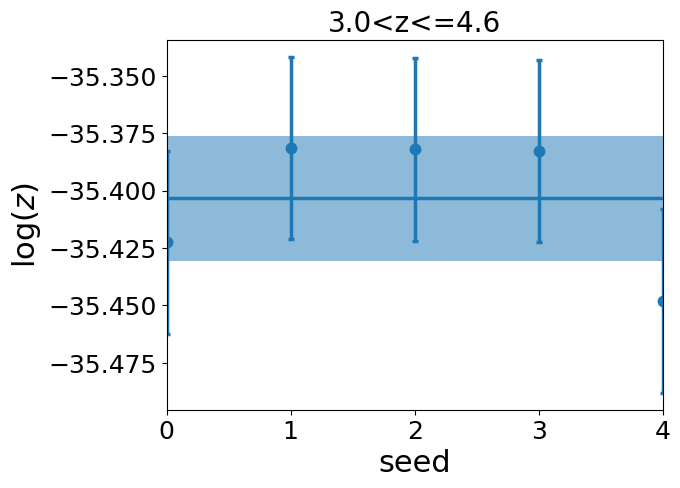

In [66]:
seeds = np.random.choice(range(1000), size=5, replace = False)

for j in z_array:

    print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))

    results_list = []
    logz_values = []
    logz_err = []
    
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_Planck_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N)) 
    ix_grid = np.ix_(rpmask[j], rpmask[j])

    # check if cov is hermitian and positive definite
    if linalg.ishermitian(C) and np.all(np.linalg.eigvals(C) > 0):
        C_factor = linalg.cho_factor(C[ix_grid])
        log_det_C = 2 * np.sum(np.log(np.diag(C_factor[0])))
        solve = lambda rhs: linalg.cho_solve(C_factor, rhs)
    else:
        print('using LU decomposition')
        C_factor = linalg.lu_factor(C[ix_grid])
        log_det_C = np.sum(np.log(np.abs(np.diag(C_factor[0])))) # does abs value make sense
        solve = lambda rhs: linalg.lu_solve(C_factor, rhs)
            
    for seed in seeds:
            
        # initialize our nested sampler
        sampler = NestedSampler(loglike, ptform, ndim, logl_args=[a_zbin[j], wp_matter_chi2[j][rpmask[j]], log_det_C, wp_chi2[j][rpmask[j]], n_q[j], nbins], nlive = nlive, rstate=np.random.default_rng(seed))
        
        # run the sampler with checkpointing
        sampler.run_nested(dlogz = dlogz)
        results = sampler.results

        logz = results.logz[-1]
        logzerr = results.logzerr[-1]
        logz_values.append(logz)
        logz_err.append(logzerr)
        results_list.append(sampler.results)
        print(f"seed={seed}: logZ = {logz:.3f} ± {logzerr:.3f}")

    # Summary statistics
    mean = np.mean(logz_values)
    std = np.std(logz_values)

    print(f"\nMean logZ: {mean:.3f}")
    print(f"Std logZ:  {std:.3f}")

    plt.errorbar(range(len(seeds)), logz_values, yerr = logz_err,  marker = 'o', markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none', label = 'per seed', linewidth = 2.5)
    plt.axhline(mean, linewidth = 2.5, label = 'mean')
    plt.fill_between(range(len(seeds)), mean-std, mean+std, alpha = 0.5, label = '$1\sigma')
    plt.ylabel('$\log(z)$')
    plt.xlabel('seed')
    plt.title('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
    # plt.legend()
    plt.xlim(0, len(seeds)-1)
    plt.show()

## Across all $z$

<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:50: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:50: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_172415/1765734348.py:35: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)
/tmp/ipykernel_172415/1765734348.py:42: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.95)
/tmp/ipykernel_172415/1765734348.py:50: SyntaxWarning: invalid escape sequence '\l'
  fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.375)
/tmp/ipykernel_172415/1765734348.py:59: S

Summary
nlive: 3000
niter: 42709
ncall: 235565
eff(%): 19.404
logz: -13.661 +/-  0.046
0<z<=1
log10(f_duty): -2.00 + 0.60/-0.38
log10(M_min): 13.17 + 1.18/-0.69
sigma: 0.62 + 0.34/-0.40



42695it [05:08, 138.37it/s, +3000 | bound: 49 | nc: 1 | ncall: 254875 | eff(%): 18.142 | loglstar:   -inf < -1.327 <    inf | logz: -8.648 +/-  0.046 | dlogz:  0.000 >  0.001]  


Summary
nlive: 3000
niter: 42695
ncall: 251875
eff(%): 18.142
logz: -8.648 +/-  0.046
1<z<=2
log10(f_duty): -2.46 + 0.76/-0.49
log10(M_min): 12.86 + 1.40/-0.88
sigma: 0.67 + 0.35/-0.45



43020it [05:46, 124.00it/s, +3000 | bound: 66 | nc: 1 | ncall: 307574 | eff(%): 15.110 | loglstar:   -inf < -13.358 <    inf | logz: -20.787 +/-  0.046 | dlogz:  0.000 >  0.001]


Summary
nlive: 3000
niter: 43020
ncall: 304574
eff(%): 15.110
logz: -20.787 +/-  0.046
2<z<=3
log10(f_duty): -2.01 + 0.95/-0.66
log10(M_min): 13.14 + 1.25/-0.85
sigma: 0.57 + 0.27/-0.37



36691it [07:21, 20.62it/s, bound: 100 | nc: 87 | ncall: 410450 | eff(%):  8.939 | loglstar:   -inf < -29.938 <    inf | logz: -35.421 +/-  0.040 | dlogz:  0.001 >  0.001]       /home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
37180it [07:39, 80.93it/s, +3000 | bound: 105 | nc: 1 | ncall: 426323 | eff(%):  9.492 | loglstar:   -inf < -29.937 <    inf | logz: -35.419 +/-  0.040 | dlogz:  0.000 >  0.001]


Summary
nlive: 3000
niter: 37180
ncall: 423323
eff(%):  9.492
logz: -35.419 +/-  0.040
3<z<=4
log10(f_duty): -3.92 + 1.72/-1.49
log10(M_min): 12.62 + 1.48/-1.25
sigma: 0.71 + 0.43/-0.43



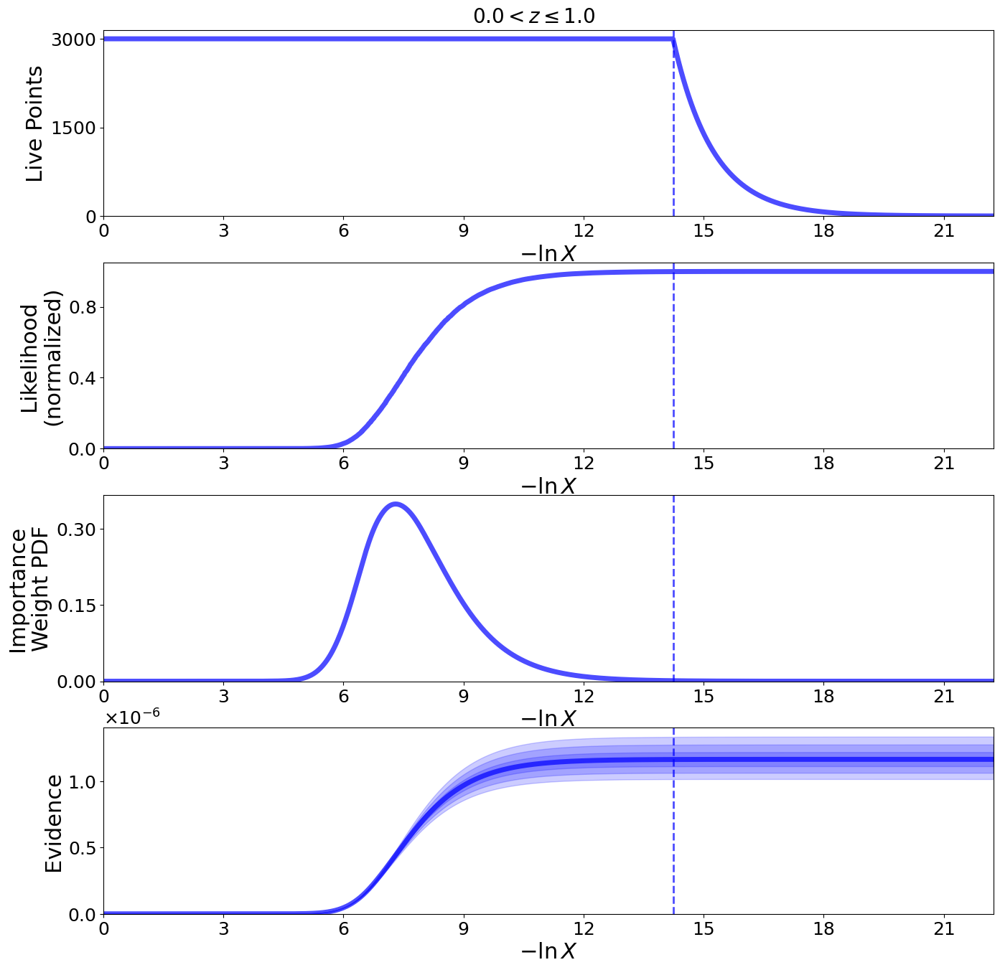

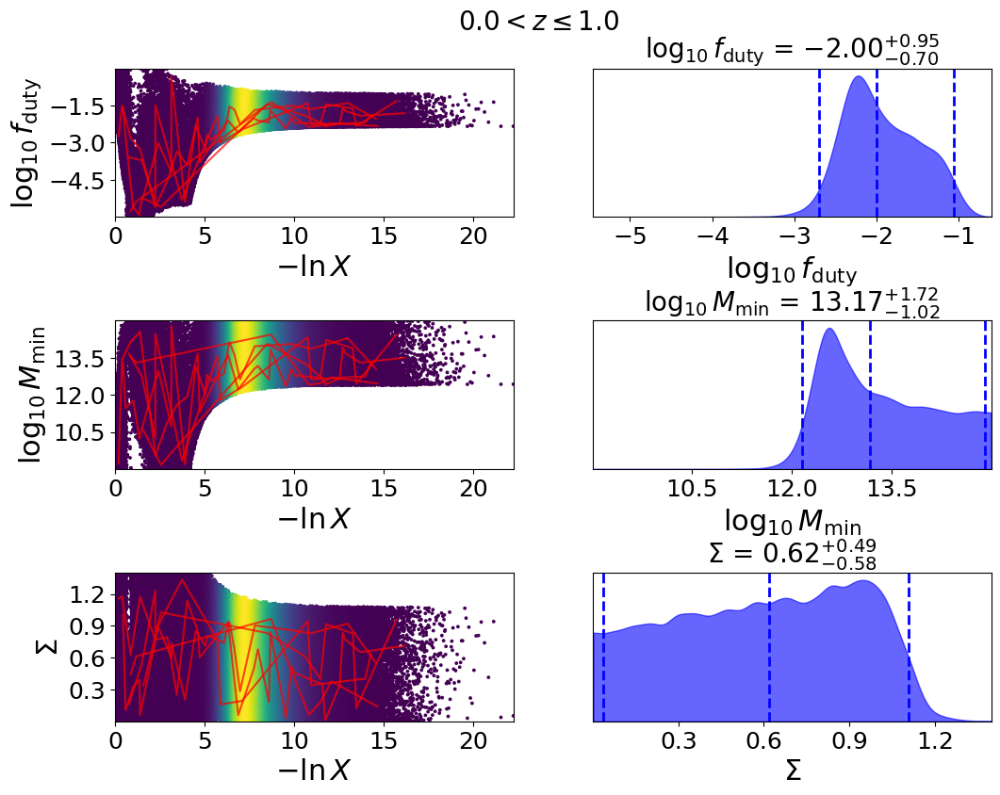

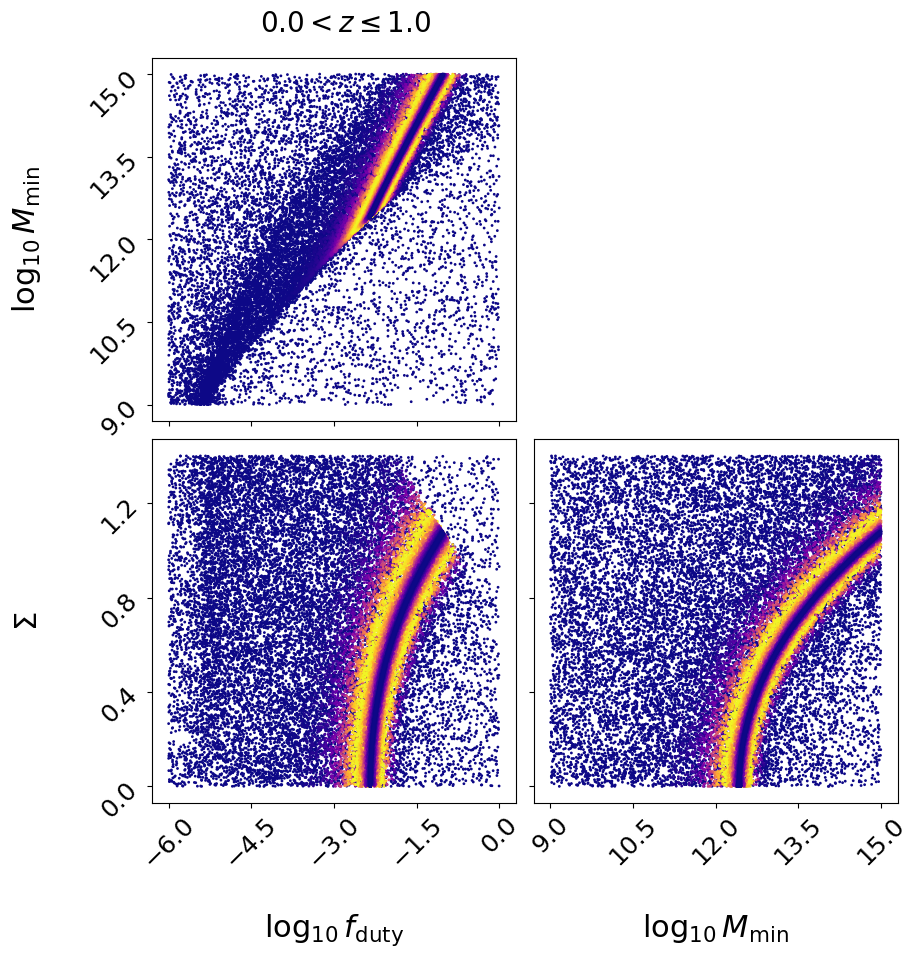

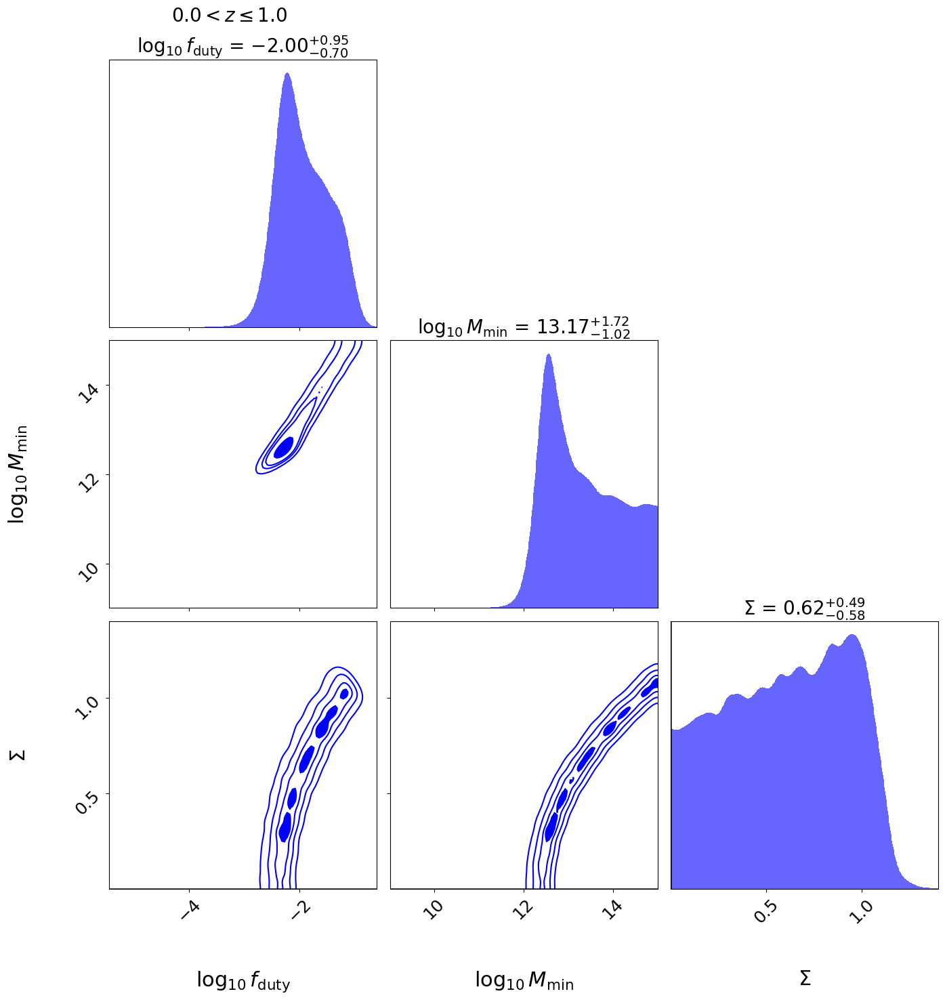

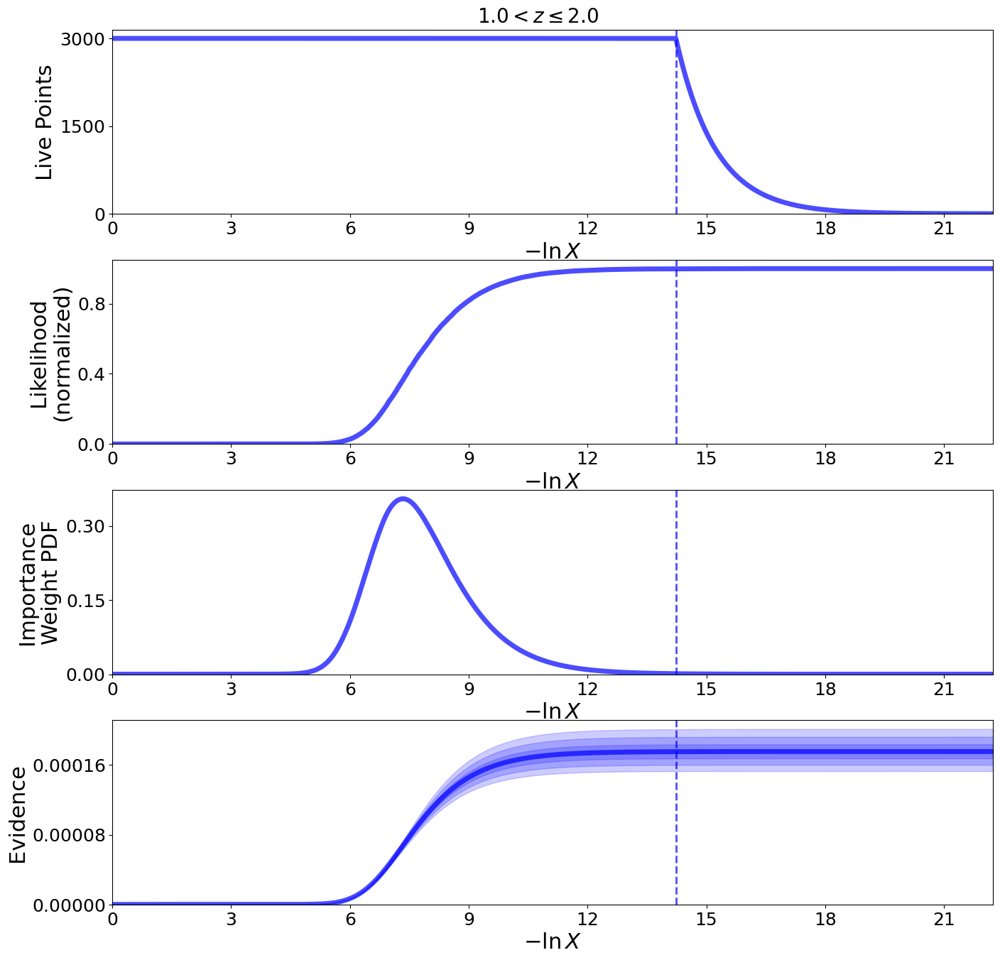

...

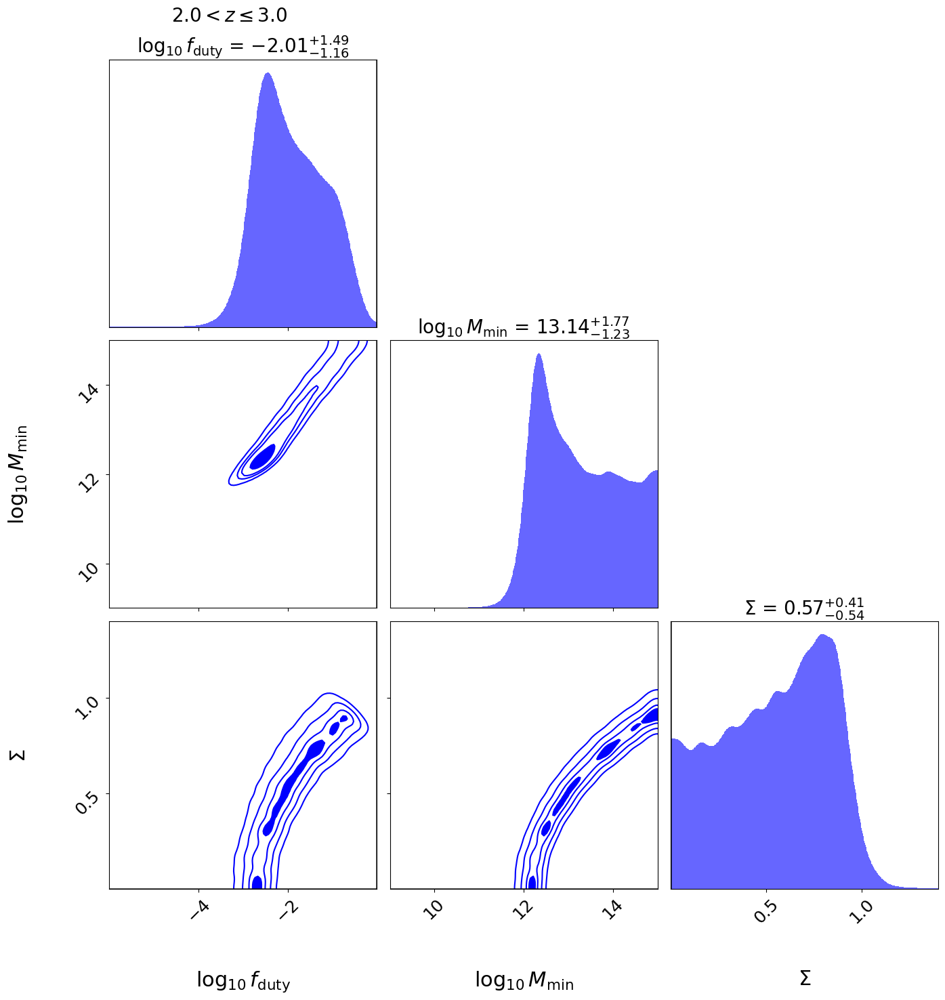

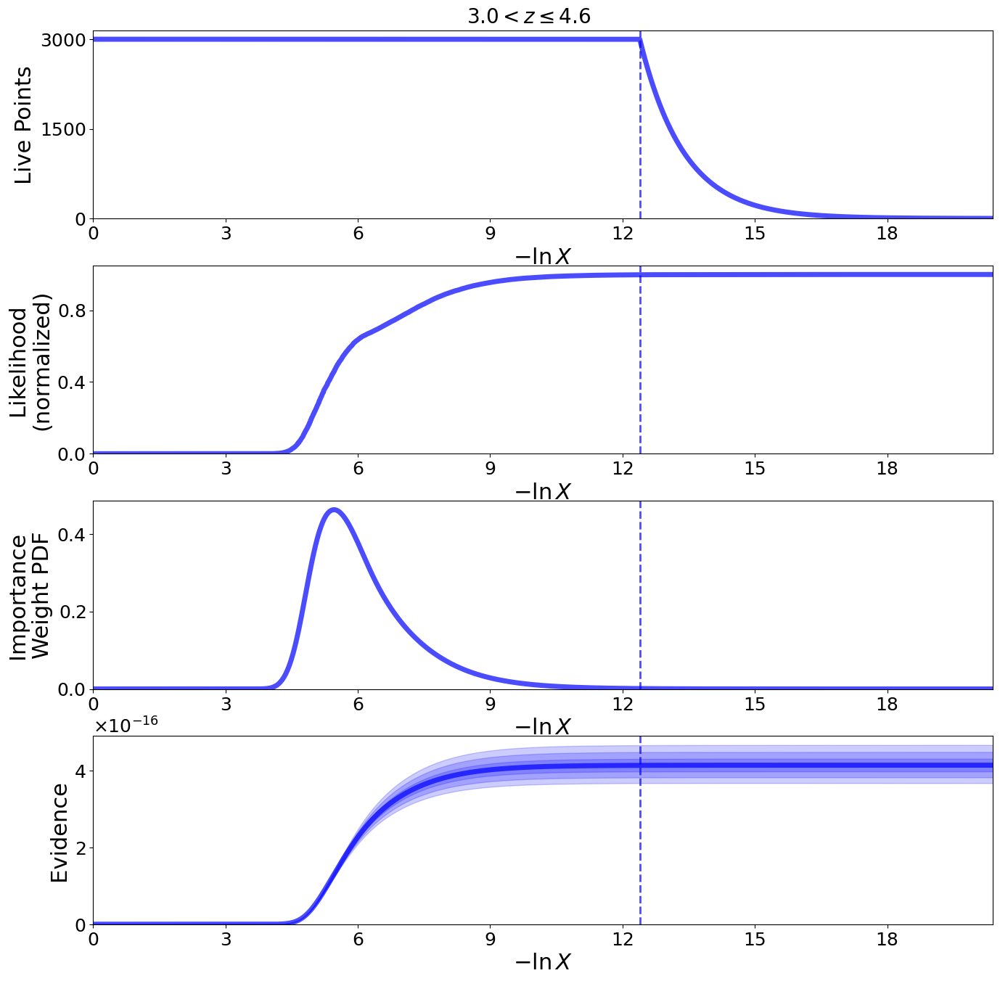

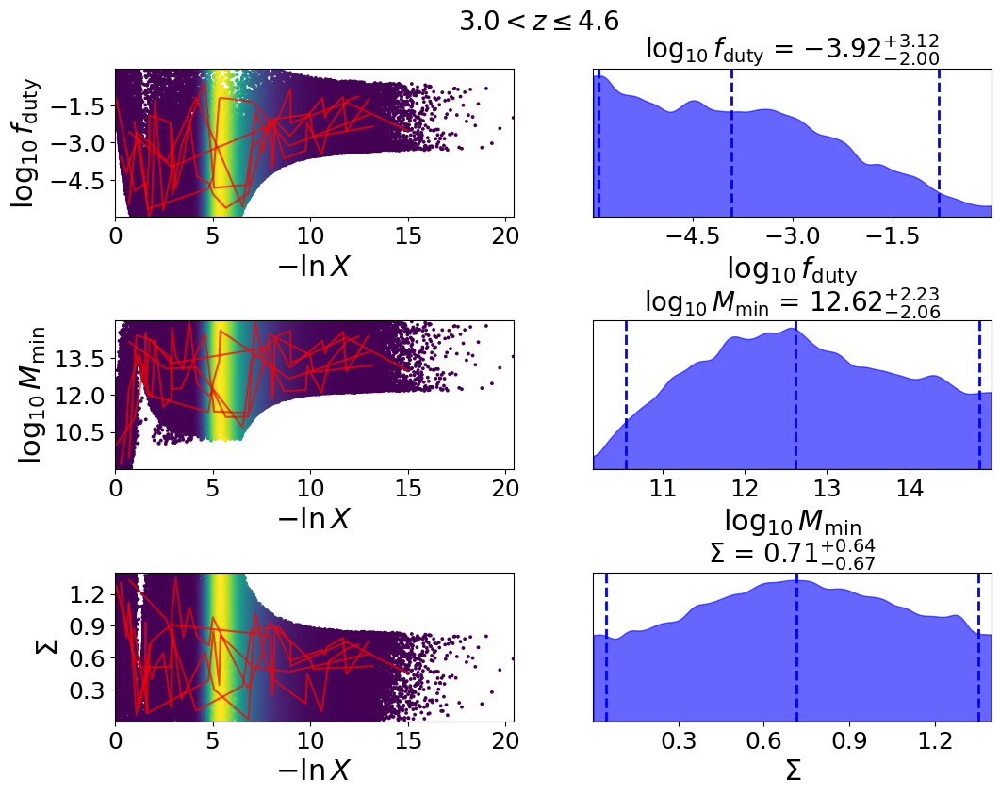

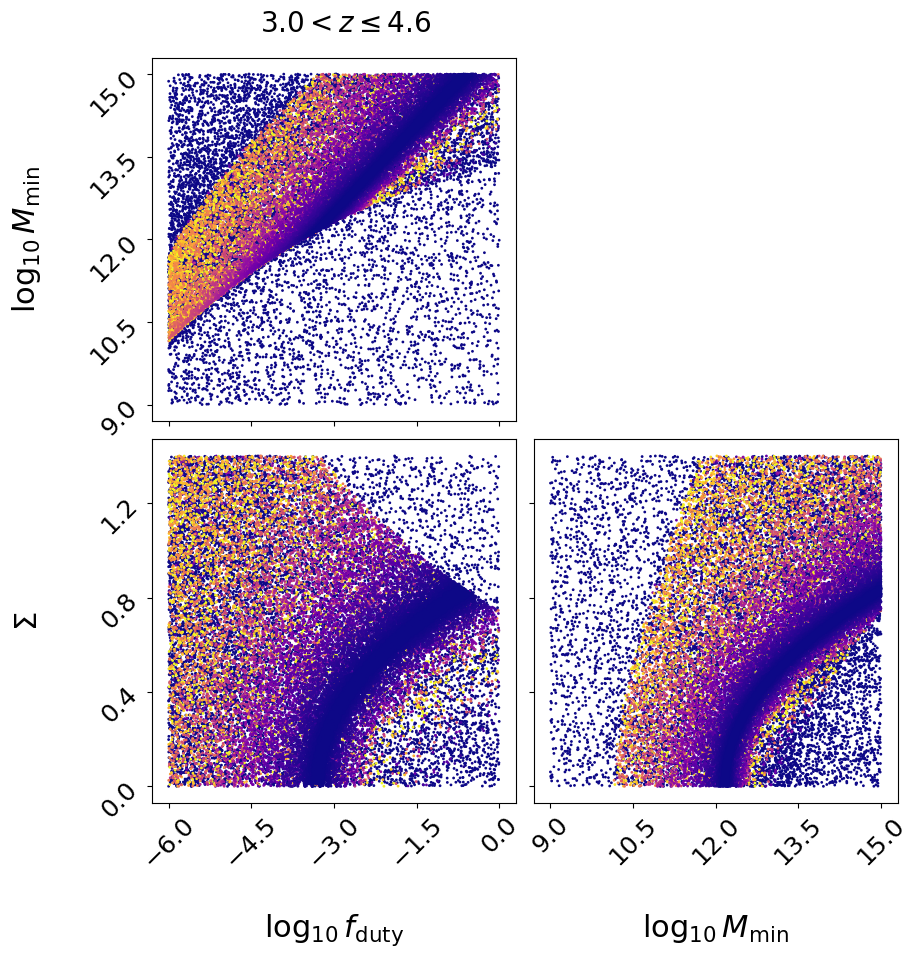

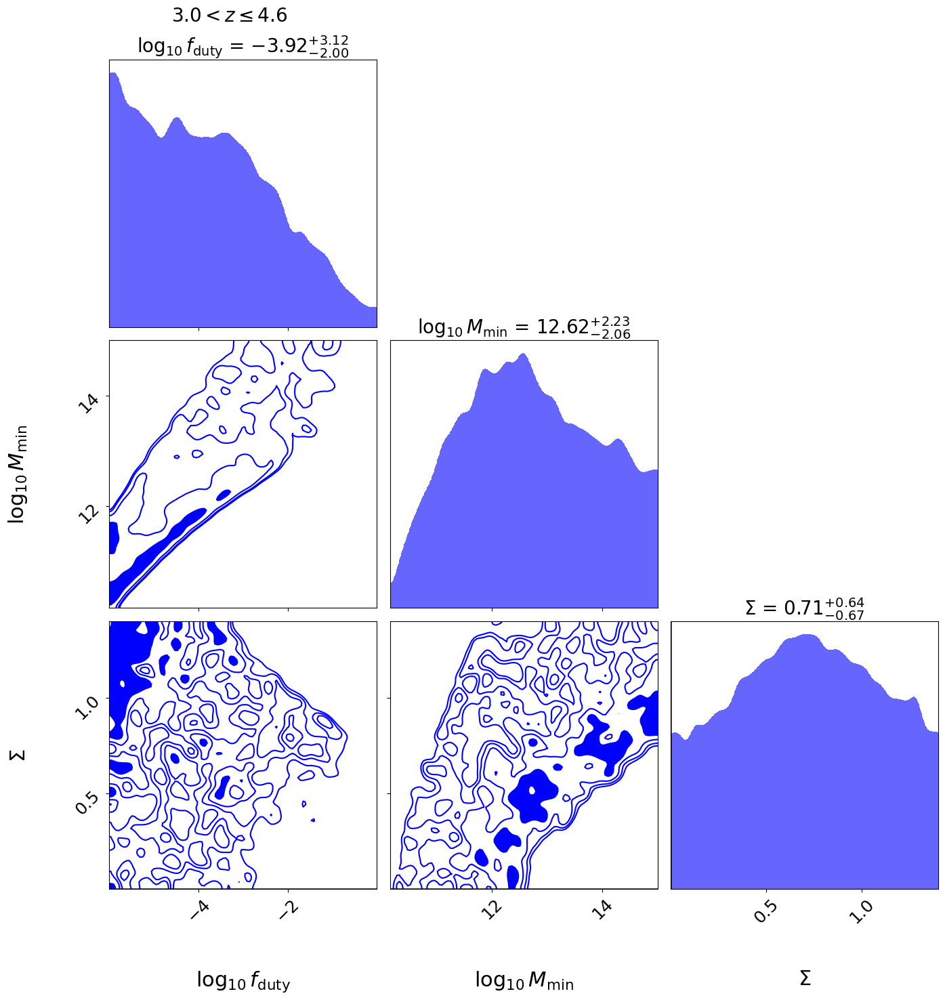

In [75]:
f_duty, M_min, sigma = [], [], []
labels = ['log10(f_duty)', 'log10(M_min)', 'sigma']
err = {i: [] for i in labels}
f_duty_samples, M_min_samples, sigma_samples = [], [], []
best_fit_params = []
logz = []
for j in z_array:

    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_Planck_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N)) 
    ix_grid = np.ix_(rpmask[j], rpmask[j])

    # check if cov is hermitian and positive definite
    if linalg.ishermitian(C) and np.all(np.linalg.eigvals(C) > 0):
        C_factor = linalg.cho_factor(C[ix_grid])
        log_det_C = 2 * np.sum(np.log(np.diag(C_factor[0])))
        solve = lambda rhs: linalg.cho_solve(C_factor, rhs)
    else:
        print('using LU decomposition')
        C_factor = linalg.lu_factor(C[ix_grid])
        log_det_C = np.sum(np.log(np.abs(np.diag(C_factor[0])))) # does abs value make sense
        solve = lambda rhs: linalg.lu_solve(C_factor, rhs)
        
    # initialize our nested sampler
    sampler = NestedSampler(loglike, ptform, ndim, logl_args=[a_zbin[j], wp_matter_chi2[j][rpmask[j]], log_det_C, wp_chi2[j][rpmask[j]], n_q[j], nbins], nlive = nlive)
    
    # run the sampler with checkpointing
    sampler.run_nested(dlogz = dlogz)
    results = sampler.results
    
    # Print out a summary of the results.
    results.summary()
    
    fig, axes = dyplot.runplot(results)  # summary (run) plot
    fig.subplots_adjust(hspace=0.25)
    fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)
    
    fig, axes = dyplot.traceplot(results, 
                                 show_titles=True,
                                 trace_cmap='viridis', connect=True,
                                 connect_highlight=range(5), labels=[r'$\log_{10}f_\mathrm{duty}$', r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$'])
    fig.subplots_adjust(hspace=0.7)
    fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.95)
    
    # initialize figure
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    # plot initial run (res1; left)
    fg, ax = dyplot.cornerpoints(results, cmap='plasma',
                                 kde=False, labels=[r'$\log_{10}f_\mathrm{duty}$', r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$'], fig=(fig, axes))
    fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.375)
    
    ## # initialize figure
    fig, axes = plt.subplots(3, 3, figsize=(15, 15))

    # plot initial run (res1; left)
    fg, ax = dyplot.cornerplot(results, color='blue', truths=np.zeros(ndim),
                               truth_color='black', show_titles=True,
                               max_n_ticks=3, quantiles=None, labels=[r'$\log_{10}f_\mathrm{duty}$', r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$'], fig=(fig, axes[:, :3]))
    fig.suptitle('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), fontsize = 20, y = 1, x = 0.25)

    samples, weights = results.samples, results.importance_weights()

    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    quantiles = [dyfunc.quantile(samples[:, i], [0.16, 0.5, 0.84], weights=weights) 
                 for i in range(samples.shape[1])]

    print('{}<z<={}'.format(j, j+1))
    for k, (lo, mid, hi) in enumerate(quantiles):
        print(f"{labels[k]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}")
        err[labels[k]].append((lo, hi))
    print()
    
    equal_weight_samples = dyfunc.resample_equal(samples, weights)
    ind = np.random.choice(range(len(equal_weight_samples)), size = 1000, replace = False)
    f_duty_samples.append(equal_weight_samples[ind][:,0])
    M_min_samples.append(equal_weight_samples[ind][:,1])
    sigma_samples.append(equal_weight_samples[ind][:,2])
    
    f_duty.append(quantiles[0][1])
    M_min.append(quantiles[1][1]) 
    sigma.append(quantiles[2][1]) 

     # Get the maximum likelihood sample from dynesty results
    idx_max = np.argmax(results.logl)
    best_fit_params.append(samples[idx_max])
    logz.append(results.logz[-1])

### Solve for $\chi_c^2=\Delta^T x$ where $Cx=\Delta$

In [76]:
def f0_GLS_solve(x, a, wp_matter, C, wp, rpbins = rbins_chi2, pibins = pibins, cosmo = cosmo_planck18, bins_m = bins, hartlap = hartlap): #M_max = M_max):  #quaia):
    
    fduty, M_min, sigma = x
    n_m=HOD_scatter(10**fduty, M_min, bins_m, sigma)
        
    wp_2h_zbin, _ = wp_2h(bins_m, n_m, a, cosmo, wp_matter, rpbins = rpbins, pibins = pibins, recenter = False)
    delta = wp-wp_2h_zbin
        
    return delta.T @ (hartlap*np.linalg.solve(C, delta))

### Add a number density constraint

In [77]:
def constraint(x, a, n_q, cosmo = cosmo_planck18, error = 0.05, bins_m = bins):
    
    fduty, M_min, sigma = x
    n_m=HOD_scatter(10**fduty, M_min, bins_m, sigma)
    
    n_q_theory = M(bins_m, n_m, a = a, cosmo = cosmo, recenter = False)[1]

    return error-np.abs(n_q_theory-n_q)/n_q

In [78]:
for j in z_array:
    
    print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
    x = f_duty[j], M_min[j], sigma[j]
    
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_Planck_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, 
                                                                                                                z_bins[j], z_bins[j+1], N))
    # chi2 = f0_GLS_solve(x, a_zbin[j], wp_matter_chi2[j], C, wp_chi2[j])
    chi2 = f0_GLS_solve(best_fit_params[j], a_zbin[j], wp_matter_chi2[j], C, wp_chi2[j])
    df = nbins-len(x)

    print('           chi^2: {:.2f}'.format(chi2))
    print('   reduced chi^2: {:.2f}'.format(chi2/df))
    print('         delta n: {:.2e}'.format(constraint(x, a_zbin[j], n_q[j])))
    print('condition number: {:.2f}'.format(np.linalg.cond(C)))
    print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi2, df)))

0.0<z<=1.0
           chi^2: 11.57
   reduced chi^2: 1.65
         delta n: 2.89e-02
condition number: 8.50
             PTE: 0.12

1.0<z<=2.0
           chi^2: 7.89
   reduced chi^2: 1.13
         delta n: 3.50e-02
condition number: 6.98
             PTE: 0.34

2.0<z<=3.0
           chi^2: 14.49
   reduced chi^2: 2.07
         delta n: 3.18e-02
condition number: 6.66
             PTE: 0.04

3.0<z<=4.6
           chi^2: 11.21
   reduced chi^2: 1.60
         delta n: -6.21e-02
condition number: 10.52
             PTE: 0.13



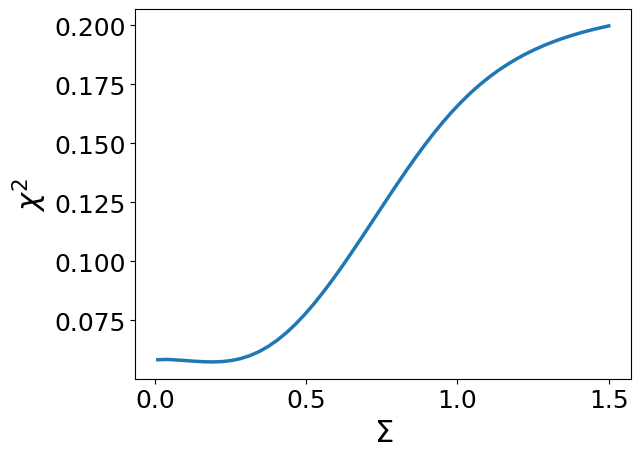

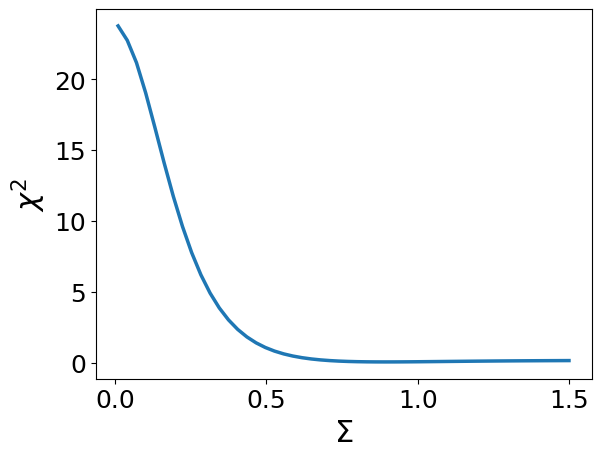

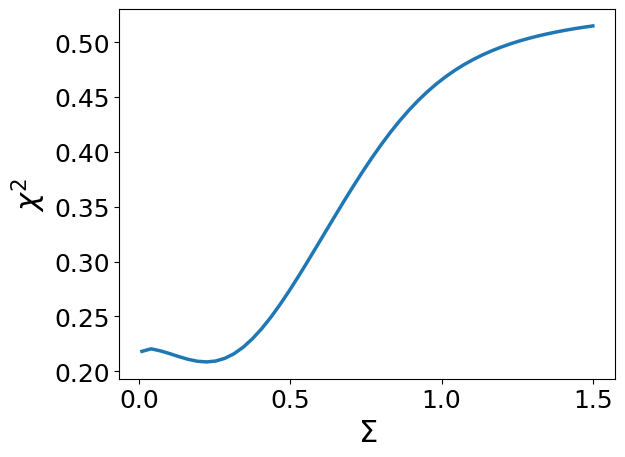

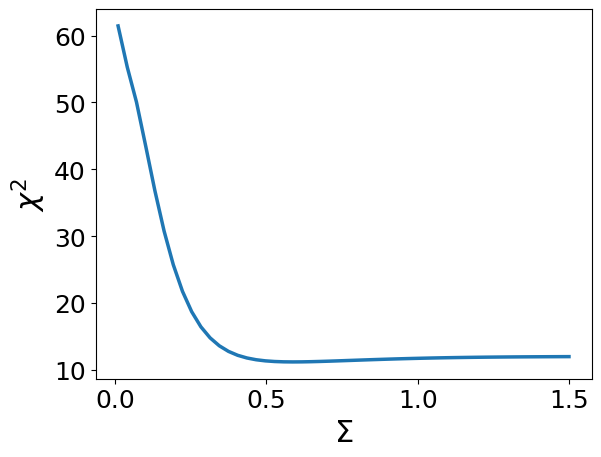

In [79]:
# Scan chi2 as a function of Sigma at fixed best-fit Mmin, fduty
sigmas = np.linspace(0.01, 1.5, 50)
for j in z_array:
    chi2_sigma = []
    for s in sigmas:
        params = [best_fit_params[j][0], best_fit_params[j][1], s]
        chi2_sigma.append(f0_GLS_solve(params, a_zbin[j], wp_matter_chi2[j], C, wp_chi2[j]))
    
    plt.plot(sigmas, chi2_sigma, linewidth = 2.5)
    plt.xlabel(r'$\Sigma$')
    plt.ylabel(r'$\chi^2$')
    plt.show()

In [80]:
best_fit_params

[array([-2.3363939 , 12.43159583,  0.05160451]),
 array([-1.86228685, 13.88501103,  0.92510196]),
 array([-2.64718712, 12.21522817,  0.03187082]),
 array([-1.9906977 , 13.55145311,  0.58822432])]

In [87]:
logz_step = np.load('../results/logz_wp.npy')

for j in z_array:
    
    print(np.exp(logz[j]-logz_step[j]))

1.0021323742451747
0.9619415402700178
0.8803448062664192
1.2220295486351014


## Plot results

In [71]:
zbin = 1/np.array(a_zbin)-1

In [72]:
z_eff = [0.5, 1.5, 2.5, 3.5]

In [73]:
fduty_err_hi = 0.002, 0.001, 0.008, 0.077
fduty_err_lo = 0.002, 0.001, 0.007, 0.034

In [74]:
M_min_err_hi = [0.04, 0.02, 0.03, 0.1]
M_min_err_lo = [0.05, 0.02, 0.03, 0.12]

In [75]:
M_min_step = np.load('../results/M_min_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask_sellentin_nlive{}_dlogz{}_penalty.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N, cosmo, nlive, dlogz))

In [76]:
err_M_min = np.load('../results/log10(M_min)_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask_sellentin_nlive{}_dlogz{}_penalty.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N, cosmo, nlive, dlogz))
M_min_lo_step, M_min_hi_step = err_M_min[:,0], err_M_min[:,1]

<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:8: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_205030/3426436667.py:2: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(zbin, M_min, color = 'darkblue', linewidth = 2.5, label = 'erfc HOD $(0\leq\Sigma<1.4)$')
/tmp/ipykernel_205030/3426436667.py:4: SyntaxWarning: invalid escape sequence '\S'
  plt.plot(zbin, M_min_step, color = 'red', linewidth = 2.5, label = 'step-function HOD $(\Sigma=0)$', linestyle = '--')
/tmp/ipykernel_205030/3426436667.py:8: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')


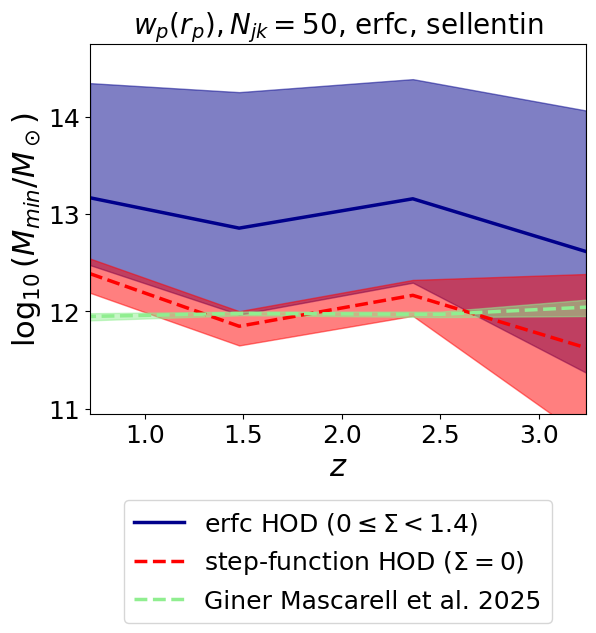

In [77]:
M_min_lo, M_min_hi = np.array(err['log10(M_min)'])[:,0], np.array(err['log10(M_min)'])[:,1]
plt.plot(zbin, M_min, color = 'darkblue', linewidth = 2.5, label = 'erfc HOD $(0\leq\Sigma<1.4)$')
plt.fill_between(zbin, M_min_lo, M_min_hi, alpha = 0.5, color = 'darkblue')
plt.plot(zbin, M_min_step, color = 'red', linewidth = 2.5, label = 'step-function HOD $(\Sigma=0)$', linestyle = '--')
plt.fill_between(zbin, M_min_lo_step, M_min_hi_step, alpha = 0.5, color = 'red')
plt.plot(z_eff, M_min_array, label = 'Giner Mascarell et al. 2025', color = 'lightgreen', linewidth = 2.5, linestyle = '--')
plt.fill_between(z_eff, M_min_array+np.array(M_min_array)/M_min_array_old*M_min_err_hi, M_min_array-np.array(M_min_array)/M_min_array_old*M_min_err_lo, alpha = 0.5, color = 'lightgreen')
plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')
plt.xlabel('$z$')
plt.legend(bbox_to_anchor = (0.5, -0.2), loc='upper center')
plt.xlim(zbin[0], zbin[-1])
plt.ylim(10.95,14.75)
plt.title(r'$w_p(r_p), N_{{jk}}={}$, erfc, sellentin'.format(N))
plt.show()

In [78]:
f_duty_step = np.load('../results/f_duty_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask_sellentin_nlive{}_dlogz{}_penalty.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N, cosmo, nlive, dlogz))

In [79]:
err_f_duty= np.load('../results/log10(f_duty)_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask_sellentin_nlive{}_dlogz{}_penalty.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], N, cosmo, nlive, dlogz))
f_duty_lo_step, f_duty_hi_step = err_f_duty[:,0], err_f_duty[:,1]

<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:8: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_205030/2542361126.py:2: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(zbin, f_duty, color = 'darkblue', linewidth = 2.5, label = 'erfc HOD $(0\leq\Sigma<1.4)$')
/tmp/ipykernel_205030/2542361126.py:4: SyntaxWarning: invalid escape sequence '\S'
  plt.plot(zbin, f_duty_step, color = 'red', linestyle = '--', linewidth = 2.5, label = 'step-function HOD $(\Sigma=0)$')
/tmp/ipykernel_205030/2542361126.py:8: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(f_{duty})$')


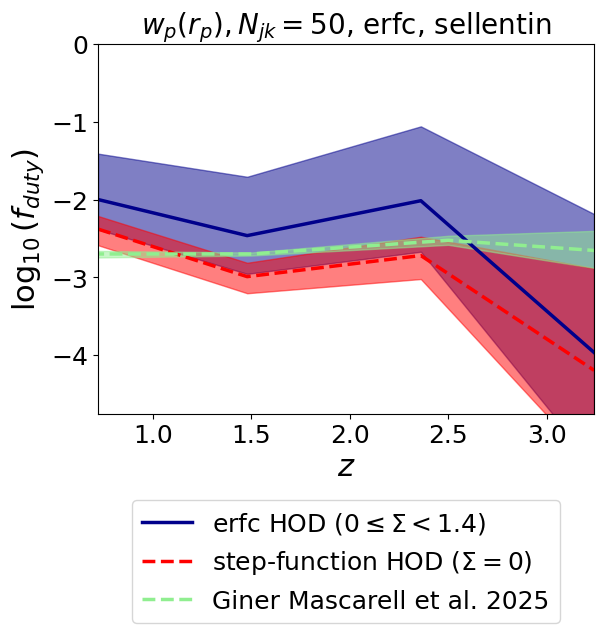

In [80]:
f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'])[:,0], np.array(err['log10(f_duty)'])[:,1]
plt.plot(zbin, f_duty, color = 'darkblue', linewidth = 2.5, label = 'erfc HOD $(0\leq\Sigma<1.4)$')
plt.fill_between(zbin, f_duty_lo, f_duty_hi, alpha = 0.5, color = 'darkblue')
plt.plot(zbin, f_duty_step, color = 'red', linestyle = '--', linewidth = 2.5, label = 'step-function HOD $(\Sigma=0)$')
plt.fill_between(zbin, f_duty_lo_step, f_duty_hi_step, alpha = 0.5, color = 'red')
plt.plot(z_eff, np.log10(fduty), label = 'Giner Mascarell et al. 2025', color = 'lightgreen', linewidth = 2.5, linestyle = '--')
plt.fill_between(z_eff, np.log10(np.array(fduty)+np.array(fduty)/fduty_old*fduty_err_hi), np.log10(np.array(fduty)-np.array(fduty)/fduty_old*fduty_err_lo), alpha = 0.5, color = 'lightgreen')
plt.ylabel('$\log_{10}(f_{duty})$')
plt.xlabel('$z$')
plt.legend(bbox_to_anchor = (0.5, -0.2), loc='upper center')
plt.xlim(zbin[0], zbin[-1])
plt.ylim(-4.75,0)
plt.title(r'$w_p(r_p), N_{{jk}}={}$, erfc, sellentin'.format(N))
plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\S'
<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_205030/3019903400.py:2: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(zbin, sigma, color = 'darkblue', linewidth = 2.5, label = 'erfc HOD $(0\leq\Sigma<1.4)$')
/tmp/ipykernel_205030/3019903400.py:4: SyntaxWarning: invalid escape sequence '\S'
  plt.axhline(0, color = 'red', linestyle = '--', label = 'step-function HOD $(\Sigma=0)$')
/tmp/ipykernel_205030/3019903400.py:5: SyntaxWarning: invalid escape sequence '\S'
  plt.ylabel('$\Sigma$')


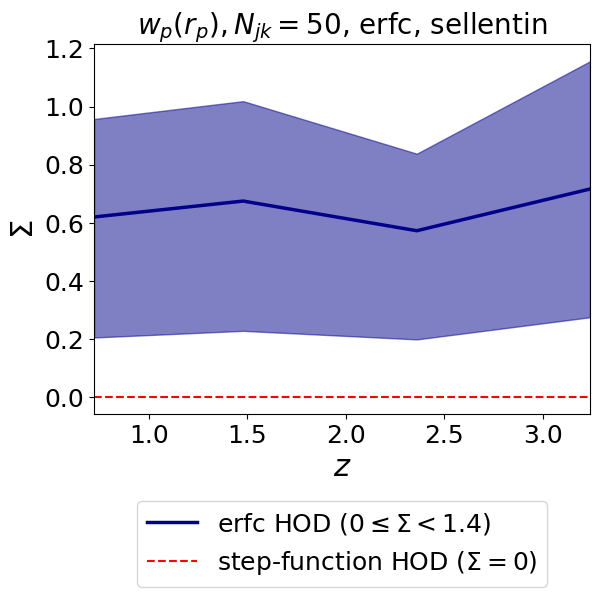

In [81]:
sigma_lo, sigma_hi = np.array(err['sigma'])[:,0], np.array(err['sigma'])[:,1]
plt.plot(zbin, sigma, color = 'darkblue', linewidth = 2.5, label = 'erfc HOD $(0\leq\Sigma<1.4)$')
plt.fill_between(zbin, sigma_lo, sigma_hi, alpha = 0.5, color = 'darkblue')
plt.axhline(0, color = 'red', linestyle = '--', label = 'step-function HOD $(\Sigma=0)$')
plt.ylabel('$\Sigma$')
plt.xlabel('$z$')
plt.legend(bbox_to_anchor = (0.5, -0.2), loc='upper center')
plt.xlim(zbin[0], zbin[-1])
plt.title(r'$w_p(r_p), N_{{jk}}={}$, erfc, sellentin'.format(N))
plt.show()

In [82]:
b_eff_wp20 = np.load('../results/b_eff_wp20_planck18.npy')

## Calculate 16th and 84th percentile of derived parameters

<>:65: SyntaxWarning: invalid escape sequence '\l'
<>:65: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_205030/1741982845.py:65: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))


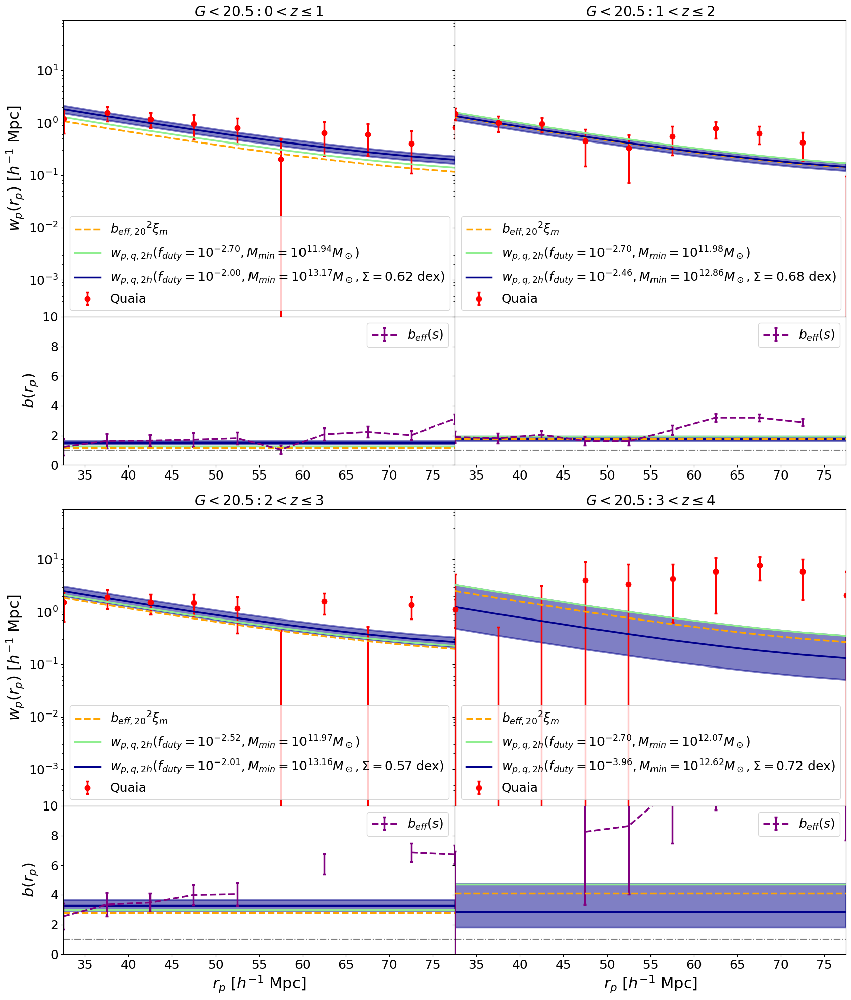

In [83]:
fig = plt.figure(figsize = (20, 24))
gs = gridspec.GridSpec(5, 2, height_ratios = [1, 0.5, 0.15, 1, 0.5], hspace = 0, wspace = 0)
ylim = 2e-4, 9e1

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j+k])
    ax2 = fig.add_subplot(gs[j+k+2])

    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_Planck_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, 
                                                                                                                z_bins[j], z_bins[j+1], N))
   
    ax1.errorbar(rpavg_chi2[j], wp_chi2[j], linewidth = 2.5, marker = 'o', label = r'Quaia', color = 'red',
                yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none')
    ax1.plot(quaia.recenter(rbins_chi2), b_eff_wp20[j]**2*wp_matter_chi2[j], linewidth = 2.5,
             label = r'${b_{eff, 20}}^2\xi_m$', color = 'orange', linestyle = '--')
    if quaia.recenter(rbins_chi2)[0] < 30:
        ax1.fill_betweenx(np.linspace(ylim[0], ylim[1]), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                          alpha = 0.5, label = 'scales excluded from fit')
        ax1.fill_betweenx(np.linspace(ylim[0], ylim[1]), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                          alpha = 0.5)

    # old fit
    wp_2h_zbin, b_q = wp_2h(bins_M_min[j], n_m_array[j], a_zbin[j], cosmo_planck18, wp_matter_chi2[j], recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5, 
             label = r'$w_{{p,q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot)$'.format(np.log10(fduty[j]), M_min_array[j]),
             color = 'lightgreen')
    ax2.axhline(b_q, linewidth = 2.5, color = 'lightgreen')

    # plot new fit
    n_m=HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j])
    wp_2h_zbin, b_q = wp_2h(bins, n_m, a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                            recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5,
             label = r'$w_{{p,q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[j], M_min[j], 
                                                                                                                           sigma[j]), 
             color = 'darkblue')
    
    wp_2h_samples, b_q_samples=[], []
    for i in range(len(ind)):
        n_m=HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i])
        wp_2h_sample, b_q_sample = wp_2h(bins, n_m, a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                                recenter = False)
        wp_2h_samples.append(wp_2h_sample)
        b_q_samples.append(b_q_sample)
    wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    b_q_16, b_q_50, b_q_84 = np.percentile(b_q_samples, [16, 50, 84])

    ax1.fill_between(quaia.recenter(rbins_chi2), wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
             color = 'darkblue')
    ax2.axhline(b_q, linewidth = 2.5, color = 'darkblue')
    ax2.fill_between(quaia.recenter(rbins_chi2), [b_q_16]*nbins, [b_q_84]*nbins, linewidth = 2.5, color = 'darkblue', alpha = 0.5)
    
    ax2.errorbar(quaia.recenter(rbins_chi2), b_wp_chi2[j], linewidth = 2.5, linestyle = '--', markeredgewidth = 2.5, capsize = 2.5,
                 color = 'purple', yerr = np.sqrt(np.diag(C)), label = '$b_{eff}(s)$')
    ax2.axhline(b_eff_wp20[j], linewidth = 2.5, color = 'orange', linestyle = '--')
    if quaia.recenter(rbins_chi2)[0] < 30:
        ax2.fill_betweenx(np.linspace(ylim[0], ylim[1]), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                          alpha = 0.5, label = 'scales excluded from fit')
        ax2.fill_betweenx(np.linspace(ylim[0], ylim[1]), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                          alpha = 0.5)
    
    if (j + k) % 6 < 2:
        ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))
    ax1.set_yscale('log')
    ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
    ax1.set_xticklabels([])
    ax1.set_ylim(ylim)
    ax1.legend()

    ax2.axhline(1, linestyle = '-.', color = 'black', alpha = 0.5)
    ax2.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
    ax2.set_ylim(0, 10)
    ax2.legend()
    
    if (j+k) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')
        ax2.set_ylabel(r'$b(r_p)$')

    else:
        ax1.set_yticklabels([])
        ax2.set_yticklabels([])

    if k != 0:
        ax2.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # 
            
    if j % 2 != 0:
        k+=4

plt.show()

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_205030/2735705837.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))


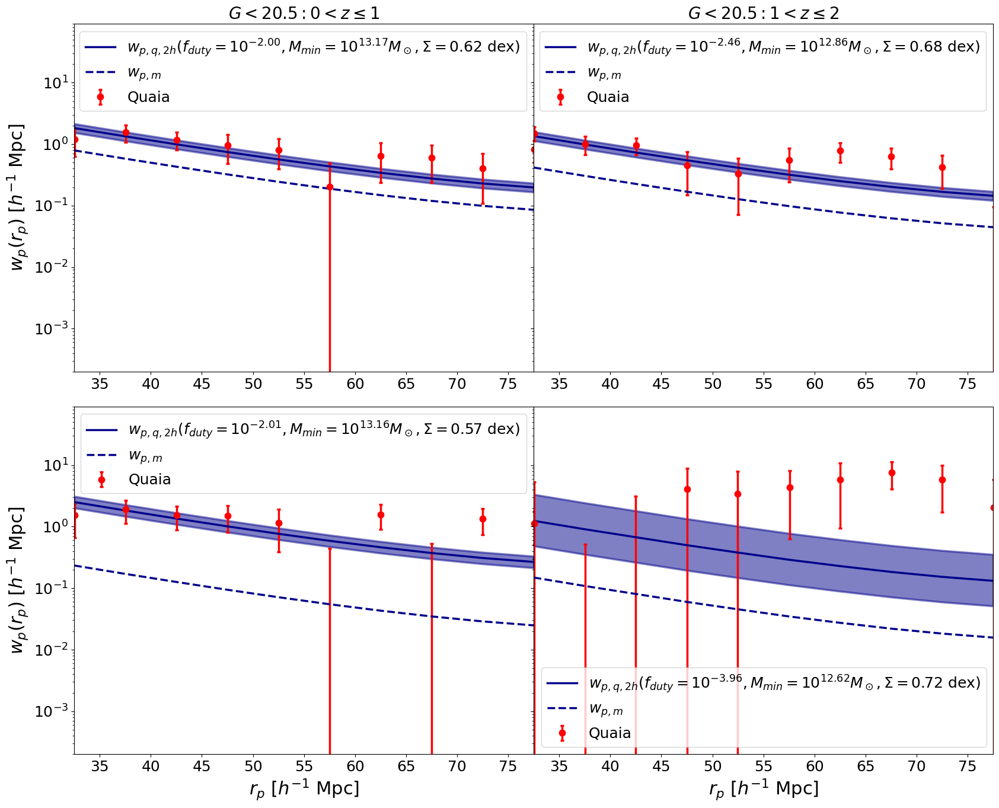

In [84]:
# remove bottom panel and just print bq somewhere
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.1, wspace = 0)

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
    
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], 
                                                                                                    N, cosmo)) # good
    
    ax1.errorbar(rpavg_chi2[j], wp_chi2[j], linewidth = 2.5, marker = 'o', label = r'Quaia', color = 'red',
                yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, capsize = 2.5, linestyle = 'none')
    if quaia.recenter(rbins_chi2)[0] < 30:
        ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                          alpha = 0.5, label = 'scales excluded from fit')
        ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                          alpha = 0.5)

    # plot new fit
    n_m=HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j])
    wp_2h_zbin, b_q = wp_2h(bins, n_m, a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                            recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5,
             label = r'$w_{{p,q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[j], M_min[j], 
                                                                                                                           sigma[j]), 
             color = 'darkblue')
    ax1.plot(quaia.recenter(rbins_chi2), wp_matter_chi2[j], linewidth = 2.5,
             label = r'$w_{{p,m}}$', linestyle = '--', 
             color = 'darkblue')

    wp_2h_samples = [wp_2h(bins, HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i]), a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                                recenter = False)[0] for i in range(len(ind))]
    wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    ax1.fill_between(quaia.recenter(rbins_chi2), wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
             color = 'darkblue')

    if j % 6 < 2:
        ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))
    ax1.set_yscale('log')
    ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
    ax1.set_ylim(ylim)
    ax1.legend()
    
    if j % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if j > 1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # 
            
    if j % 2 != 0:
        k+=2

plt.show()

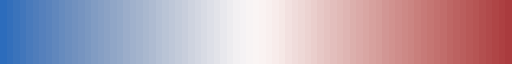

In [85]:
cmap_M_min = sns.color_palette("vlag", n_colors = len(bins))
palette_M_min = matplotlib.colors.ListedColormap(cmap_M_min)
palette_M_min

<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:61: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:61: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_205030/2764510377.py:42: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))
/tmp/ipykernel_205030/2764510377.py:61: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')


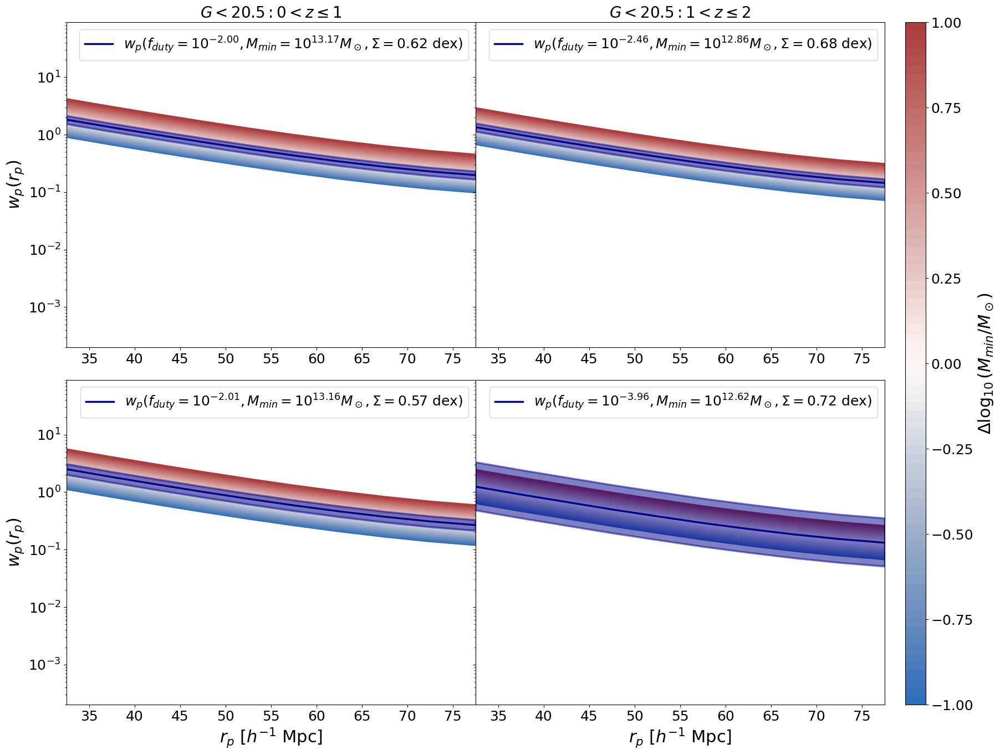

In [86]:
# remove bottom panel and just print bq somewhere
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 4, hspace = 0.1, wspace = 0, width_ratios = [1,1,0.05,0.05])

l = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j+l])
    
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], 
                                                                                                    N, cosmo)) # good
    
    if quaia.recenter(rbins_chi2)[0] < 30:
        ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                      alpha = 0.5, label = 'scales excluded from fit')
        ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                      alpha = 0.5)

    # plot new fit
    n_m=HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j])
    wp_2h_zbin, b_q = wp_2h(bins, n_m, a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                            recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5,
             label = r'$w_p(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[j], M_min[j], 
                                                                                                                           sigma[j]), 
             color = 'darkblue')

    for k in range(len(bins)):
        M_min_k = M_min[j]-1+k/int(len(bins)/2)
        n_m=HOD_scatter(10**f_duty[j], M_min_k, bins, sigma[j])
        wp_2h_sample, _ = wp_2h(bins, n_m, a_zbin[j], 
                 cosmo_planck18, wp_matter_chi2[j], recenter = False)
        ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))
        
    wp_2h_samples = [wp_2h(bins, HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i]), a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                                recenter = False)[0] for i in range(len(ind))]
    wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    ax1.fill_between(quaia.recenter(rbins_chi2), wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
             color = 'darkblue')   
    
    if j % 6 < 2:
        ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))
    ax1.set_yscale('log')
    ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
    ax1.set_ylim(ylim)
    ax1.legend()
    
    if j % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$')

    else:
        ax1.set_yticklabels([])

    if j > 1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # 
            
    if j == 1:
        l+=2

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

In [87]:
sigma_k_array = np.linspace(0,1.4, 51) #-4

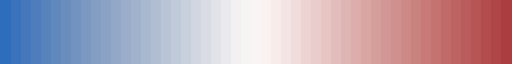

In [88]:
cmap_sigma = sns.color_palette("vlag", n_colors = len(sigma_k_array))
palette_sigma = matplotlib.colors.ListedColormap(cmap_sigma)
palette_sigma

In [89]:
delta = 0.1

<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:61: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:61: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_205030/3578362179.py:42: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))
/tmp/ipykernel_205030/3578362179.py:61: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \Sigma$ dex')


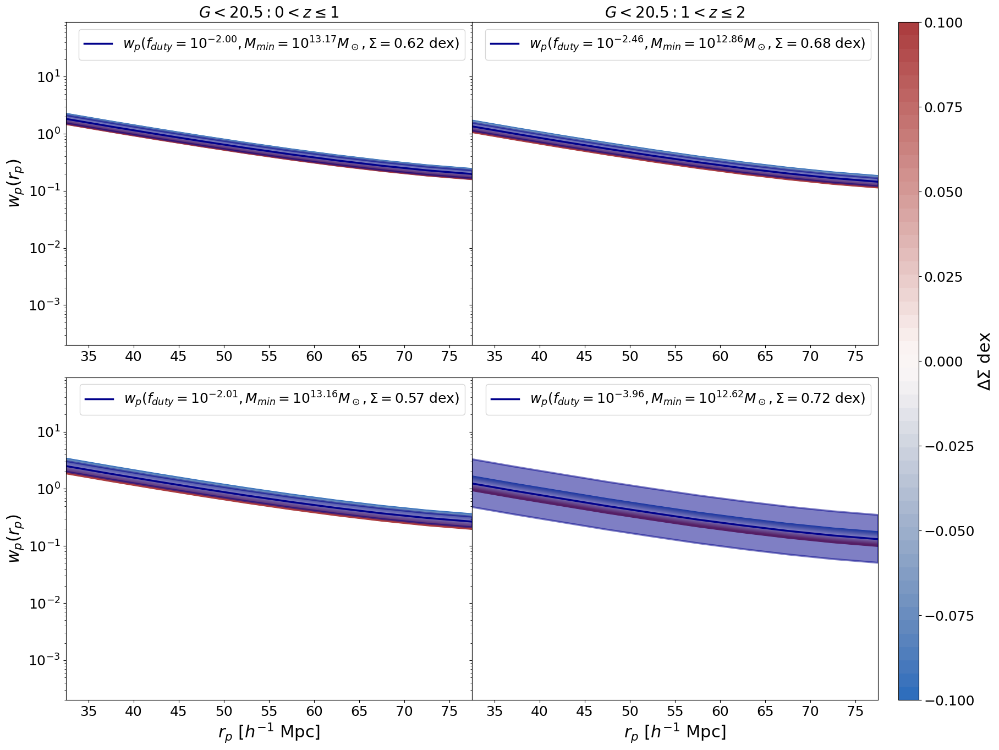

In [90]:
# remove bottom panel and just print bq somewhere
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 4, hspace = 0.1, wspace = 0, width_ratios = [1,1,0.05,0.05])

l = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j+l])
    
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{}_N{}_{}_MC_mask.npy'.format(G_hi, rmin, rmax, nbins, pimax, z_bins[j], z_bins[j+1], 
                                                                                                    N, cosmo)) # good
    
    if quaia.recenter(rbins_chi2)[0] < 30:
        ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = quaia.recenter(rbins_chi2)[0], x2 = 30, color = 'grey', 
                          alpha = 0.5, label = 'scales excluded from fit')
        ax1.fill_betweenx(np.linspace(3e-4, 5e1), x1 = 80, x2 = quaia.recenter(rbins_chi2)[-1], color = 'grey', 
                          alpha = 0.5)

    # plot new fit
    n_m=HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j])
    wp_2h_zbin, b_q = wp_2h(bins, n_m, a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                            recenter = False)
    ax1.plot(quaia.recenter(rbins_chi2), wp_2h_zbin, linewidth = 2.5,
             label = r'$w_p(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[j], M_min[j], 
                                                                                                                           sigma[j]), 
             color = 'darkblue')

    for k in range(len(sigma_k_array)):
        sigma_k = sigma[j]+delta*(-1+k/int(len(sigma_k_array)/2))
        n_m=HOD_scatter(10**f_duty[j], M_min[j], bins, sigma_k)
        wp_2h_sample, _ = wp_2h(bins, n_m, a_zbin[j], 
                 cosmo_planck18, wp_matter_chi2[j], recenter = False)
        ax1.plot(quaia.recenter(rbins_chi2), wp_2h_sample, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

    wp_2h_samples = [wp_2h(bins, HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i]), a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                                recenter = False)[0] for i in range(len(ind))]
    wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
    ax1.fill_between(quaia.recenter(rbins_chi2), wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
             color = 'darkblue')   
    
    if j % 6 < 2:
        ax1.set_title('$G<{}: {:.0f}<z \leq{:.0f}$'.format(G_hi, j, j+1))
    ax1.set_yscale('log')
    ax1.set_xlim(quaia.recenter(rbins_chi2)[0], quaia.recenter(rbins_chi2)[-1])
    ax1.set_ylim(ylim)
    ax1.legend()
    
    if j % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$')

    else:
        ax1.set_yticklabels([])

    if j > 1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # 
            
    if j == 1:
        l+=2

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), cax = fig.add_subplot(gs[:,-1]), 
                label = '$\Delta \Sigma$ dex')
plt.show()

In [91]:
b_q_percentile = []
for j in z_array:
    b_q_samples=[wp_2h(bins, HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i]), a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
                                recenter = False)[1]for i in range(len(ind))]
    b_q_percentile.append(np.percentile(b_q_samples, [16, 84]))
b_q_lo, b_q_hi = np.array(b_q_percentile).T

<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:85: SyntaxWarning: invalid escape sequence '\D'
<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:85: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_205030/271428657.py:38: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_205030/271428657.py:85: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \Sigma$ dex')


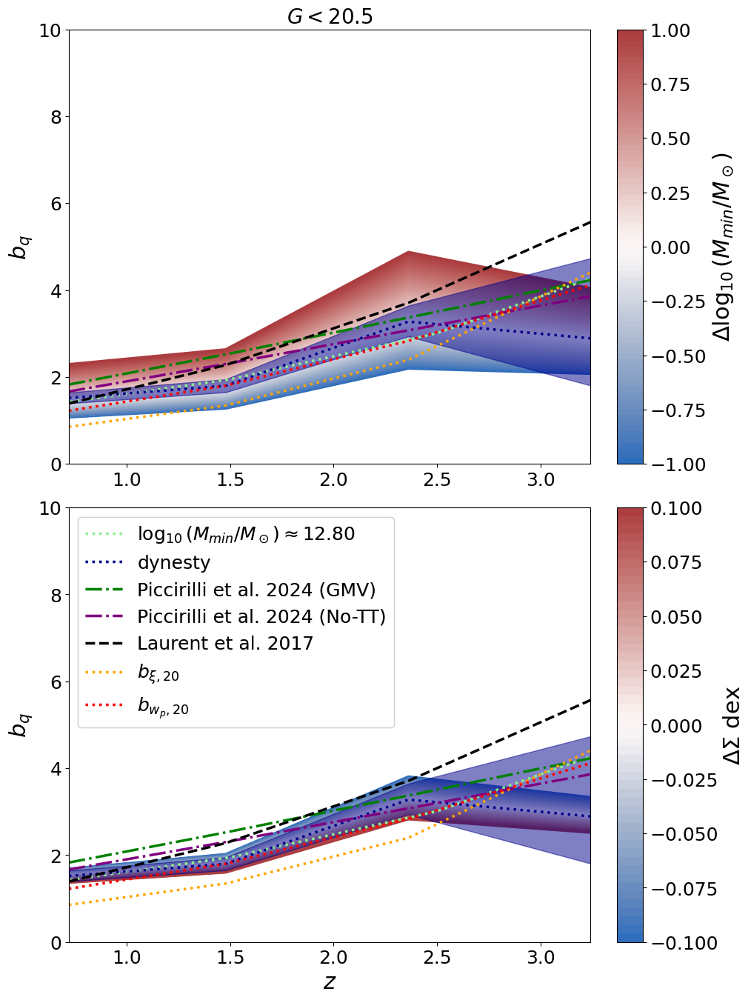

In [92]:
fig = plt.figure(figsize = (10, 16))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(2, 3, width_ratios = [1, 0.05, 0.05], wspace = 0, hspace = 0.1)
ax1 = fig.add_subplot(gs[0])
    
b_q = [wp_2h(bins_M_min[j], n_m_array[j], a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
             recenter = False)[1] for j in z_array]
ax1.plot(z_eff, b_q, linewidth = 2.5, color = 'lightgreen', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

b_q=[wp_2h(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]), a_zbin[j], cosmo_planck18, 
                 wp_matter_chi2[j], recenter = False)[1] for j in z_array]
ax1.plot(zbin, b_q, linewidth = 2.5, color = 'darkblue', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, b_q_lo, b_q_hi, alpha = 0.5, color = 'darkblue') # color = cmaps[i][j], alpha = (l+1)/len(bins))

for k in range(len(bins)):
        
    b_q=[wp_2h(bins, HOD_scatter(10**f_duty[j], M_min[j]-1+k/int(len(bins)/2), bins, sigma[j]), a_zbin[j], 
                     cosmo_planck18, wp_matter_chi2[j], recenter = False)[1] for j in z_array]
    ax1.plot(zbin, b_q, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.plot(zbin, b_quaia(1.26, a_zbin), linestyle = '-.', linewidth = 2.5, 
         label = 'Piccirilli et al. 2024 (GMV)', color = 'green') # eq 3.6 in https://arxiv.org/abs/2402.05761
ax1.plot(zbin, b_quaia(1.15, a_zbin), linestyle = '-.', linewidth = 2.5, 
         label = 'Piccirilli et al. 2024 (No-TT)', color = 'purple') # eq 3.6 in https://arxiv.org/abs/2402.05761
ax1.plot(zbin, b_eboss(zbin), linestyle = '--', linewidth = 2.5, label = 'Laurent et al. 2017', 
         color = 'black') # eq 3.6 in https://arxiv.org/abs/2402.05761

ax1.plot(zbin, b_cf20, linestyle = ':', linewidth = 2.5, label = r'$b_{\xi, 20}$', color = 'orange') 
ax1.plot(zbin, b_wp20, linestyle = ':', linewidth = 2.5, label = '$b_{w_p, 20}$', color = 'red') 

ax1.set_title('$G<{}$'.format(G_hi))

ax1.set_ylim(0, 10)
ax1.set_xlim(zbin[0], zbin[-1])
ax1.set_ylabel(r'$b_q$')

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[0,-1]), 
                    label = '$\Delta \log_{10}(M_{min}/M_\odot)$')

ax1 = fig.add_subplot(gs[3])
    
b_q = [wp_2h(bins_M_min[j], n_m_array[j], a_zbin[j], cosmo_planck18, wp_matter_chi2[j], 
             recenter = False)[1] for j in z_array]
ax1.plot(z_eff, b_q, linewidth = 2.5, color = 'lightgreen', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

b_q=[wp_2h(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]), a_zbin[j], cosmo_planck18, 
                 wp_matter_chi2[j], recenter = False)[1] for j in z_array]
ax1.plot(zbin, b_q, linewidth = 2.5, color = 'darkblue', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, b_q_lo, b_q_hi, alpha = 0.5, color = 'darkblue') # color = cmaps[i][j], alpha = (l+1)/len(bins))

for k in range(len(sigma_k_array)):
        
    b_q=[wp_2h(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]+delta*(-1+k/int(len(sigma_k_array)/2))), a_zbin[j], 
                     cosmo_planck18, wp_matter_chi2[j], recenter = False)[1] for j in z_array]
    ax1.plot(zbin, b_q, linewidth = 2.5, color = cmap_sigma[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.plot(zbin, b_quaia(1.26, a_zbin), linestyle = '-.', linewidth = 2.5, 
         label = 'Piccirilli et al. 2024 (GMV)', color = 'green') # eq 3.6 in https://arxiv.org/abs/2402.05761
ax1.plot(zbin, b_quaia(1.15, a_zbin), linestyle = '-.', linewidth = 2.5, 
         label = 'Piccirilli et al. 2024 (No-TT)', color = 'purple') # eq 3.6 in https://arxiv.org/abs/2402.05761
ax1.plot(zbin, b_eboss(zbin), linestyle = '--', linewidth = 2.5, label = 'Laurent et al. 2017', 
         color = 'black') # eq 3.6 in https://arxiv.org/abs/2402.05761

ax1.plot(zbin, b_cf20, linestyle = ':', linewidth = 2.5, label = r'$b_{\xi, 20}$', color = 'orange') 
ax1.plot(zbin, b_wp20, linestyle = ':', linewidth = 2.5, label = '$b_{w_p, 20}$', color = 'red') 

ax1.set_xlabel('$z$')
ax1.set_ylim(0, 10)
ax1.set_xlim(zbin[0], zbin[-1])
ax1.set_ylabel(r'$b_q$')

custom_lines = [Line2D([0], [0], color = 'lightgreen', linestyle = ':', linewidth = 2.5),
                Line2D([0], [0], color = 'darkblue', linestyle = ':', linewidth = 2.5),
                Line2D([0], [0], color = 'green', linestyle = '-.', linewidth = 2.5), 
                Line2D([0], [0], color = 'purple', linestyle = '-.', linewidth = 2.5),
                Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                Line2D([0], [0], color = 'orange', linestyle = ':', linewidth = 2.5), 
                Line2D([0], [0], color = 'red', linestyle = ':', linewidth = 2.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)\approx{:.2f}$'.format(12.8), 
                                          'dynesty', 'Piccirilli et al. 2024 (GMV)', 'Piccirilli et al. 2024 (No-TT)', 
                                          'Laurent et al. 2017', r'$b_{\xi, 20}$', '$b_{w_p, 20}$'])
fig.add_artist(second_legend)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), cax = fig.add_subplot(gs[1,-1]), 
                    label = '$\Delta \Sigma$ dex')
plt.show()

In [93]:
M_h_percentile = []
for j in z_array:
    M_h_samples=[]
    for i in range(len(ind)):
        n_m=HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i])
        M_h_samples.append(M(bins, n_m, a = a_zbin[j], cosmo = cosmo_planck18, 
         recenter = False)[0])
    M_h_percentile.append(np.percentile(M_h_samples, [16, 84]))
M_h_lo, M_h_hi = np.array(M_h_percentile).T

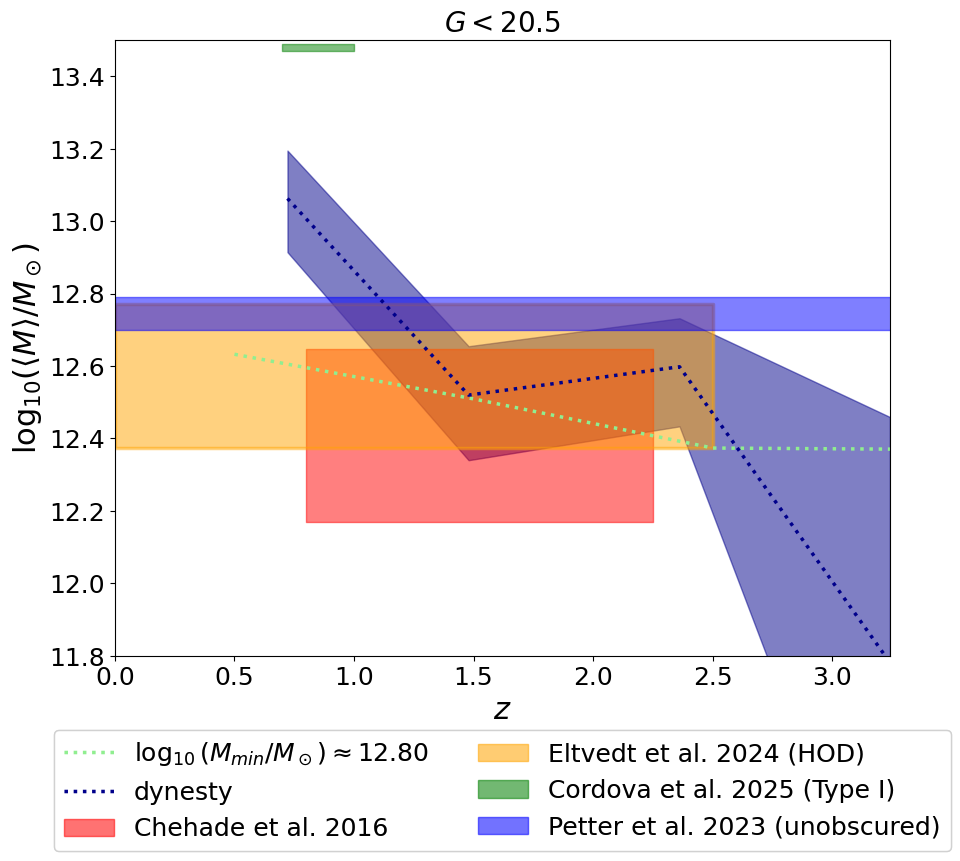

In [94]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])
    
M_h = [M(bins_M_min[j], n_m_array[j], a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
ax1.plot(z_eff, np.log10(M_h), linewidth = 2.5, color = 'lightgreen', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

M_h=[M(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, 
         recenter = False)[0] for j in z_array]
ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, color = 'darkblue', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = 'darkblue') # color = cmaps[i][j], alpha = (l+1)/len(bins))

z = np.linspace(0.8, 2.25)
ax1.fill_between(z, [np.log10(1e12/Planck18.h)]*len(z), [np.log10(3e12/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Chehade et al. 2016', color = 'red')
ax1.set_title('$G<{}$'.format(G_hi))
ax1.fill_between(np.linspace(0, 2.5), [np.log10(1.6e12/Planck18.h)]*len(z), [np.log10(4e12/Planck18.h)]*len(z), linewidth = 2.5, 
                 label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
ax1.fill_between(np.linspace(0.7, 1), [13.47]*len(z), [13.49]*len(z), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

# check redshift range and check cordova type i was right to include because conflicts with this
ax1.fill_between(np.linspace(0, 3.5), [np.log10(10**12.53/Planck18.h)]*len(z), [np.log10(10**12.62/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Petter et al. 2023 (unobscured)', color = 'blue')

custom_lines = [Line2D([0], [0], color = 'lightgreen', linestyle = ':', linewidth = 2.5), 
                Line2D([0], [0], color = 'darkblue', linestyle = ':', linewidth = 2.5), mpatches.Patch(color='red', alpha = 0.5), 
                mpatches.Patch(color='orange', alpha = 0.5), mpatches.Patch(color='green', alpha = 0.5), mpatches.Patch(color='blue', alpha = 0.5)]
second_legend = ax1.legend(custom_lines, [#'Giner Mascarell et al. 2025', 
                                          r'$\log_{{10}}(M_{{min}}/M_\odot)\approx{:.2f}$'.format(12.8), 
                                          'dynesty', 'Chehade et al. 2016', 'Eltvedt et al. 2024 (HOD)', 'Cordova et al. 2025 (Type I)', 'Petter et al. 2023 (unobscured)'], 
                           ncol = 2, bbox_to_anchor = (0.5, -0.1), loc='upper center')
fig.add_artist(second_legend)

ax1.set_xlabel('$z$')
ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
ax1.set_xlim(0, zbin[-1])
ax1.set_ylim(11.8, 13.5)

plt.show()

<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:81: SyntaxWarning: invalid escape sequence '\D'
<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:81: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_205030/3427163053.py:38: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_205030/3427163053.py:81: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \Sigma$ dex')


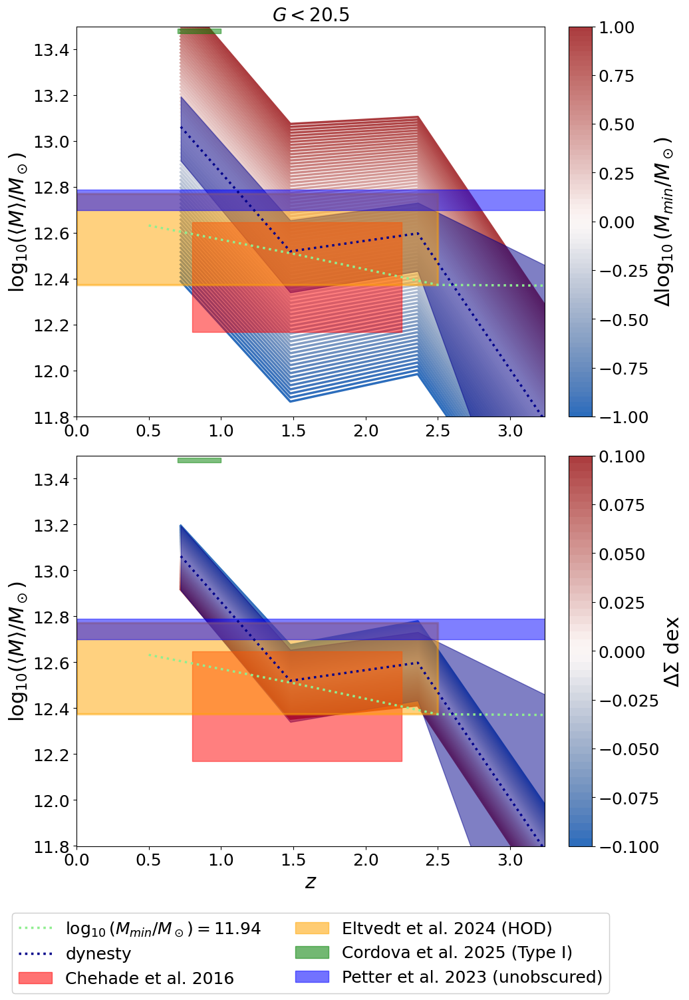

In [95]:
fig = plt.figure(figsize = (10, 16))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(2, 3, width_ratios = [1, 0.05, 0.05], wspace = 0, hspace = 0.1)
ax1 = fig.add_subplot(gs[0])

for k in range(len(bins)):
    
    M_h=[M(bins, HOD_scatter(10**f_duty[j], M_min[j]-1+k/int(len(bins)/2), bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
    ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, 
             label = r'$f_{{duty}}: {:.2f}\%-{:.2f}\%, M_{{min}}:{:.2f} M_\odot$'.format(fduty[0]*100, fduty[-1]*100, np.log10(bins[k])),
             color = cmap_M_min[k], zorder = 0) #, alpha = (1+k)/len(bins))
    
M_h = [M(bins_M_min[j], n_m_array[j], a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
ax1.plot(z_eff, np.log10(M_h), linewidth = 2.5, color = 'lightgreen', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

M_h=[M(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, 
         recenter = False)[0] for j in z_array]
ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, color = 'darkblue', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = 'darkblue') # color = cmaps[i][j], alpha = (l+1)/len(bins))

z = np.linspace(0.8, 2.25)
ax1.fill_between(z, [np.log10(1e12/Planck18.h)]*len(z), [np.log10(3e12/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Chehade et al. 2016', color = 'red')
ax1.set_title('$G<{}$'.format(G_hi))
ax1.fill_between(np.linspace(0, 2.5), [np.log10(1.6e12/Planck18.h)]*len(z), [np.log10(4e12/Planck18.h)]*len(z), linewidth = 2.5, 
                 label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
ax1.fill_between(np.linspace(0.7, 1), [13.47]*len(z), [13.49]*len(z), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

# check redshift range and check cordova type i was right to include because conflicts with this
ax1.fill_between(np.linspace(0, 3.5), [np.log10(10**12.53/Planck18.h)]*len(z), [np.log10(10**12.62/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Petter et al. 2023 (unobscured)', color = 'blue')

ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
ax1.set_xlim(0, zbin[-1])
ax1.set_ylim(11.8, 13.5)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[0,-1]), 
                    label = '$\Delta \log_{10}(M_{min}/M_\odot)$')

ax1 = fig.add_subplot(gs[3])

for k in range(len(sigma_k_array)):
    
    M_h=[M(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]+delta*(-1+k/int(len(sigma_k_array)/2))), a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
    ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, 
             label = r'$f_{{duty}}: {:.2f}\%-{:.2f}\%, M_{{min}}:{:.2f} M_\odot$'.format(fduty[0]*100, fduty[-1]*100, np.log10(bins[k])),
             color = cmap_sigma[k], zorder = 0) #, alpha = (1+k)/len(bins))
    
M_h = [M(bins_M_min[j], n_m_array[j], a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
ax1.plot(z_eff, np.log10(M_h), linewidth = 2.5, color = 'lightgreen', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

M_h=[M(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, 
         recenter = False)[0] for j in z_array]
ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, color = 'darkblue', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = 'darkblue') # color = cmaps[i][j], alpha = (l+1)/len(bins))

z = np.linspace(0.8, 2.25)
ax1.fill_between(z, [np.log10(1e12/Planck18.h)]*len(z), [np.log10(3e12/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Chehade et al. 2016', color = 'red')
ax1.fill_between(np.linspace(0, 2.5), [np.log10(1.6e12/Planck18.h)]*len(z), [np.log10(4e12/Planck18.h)]*len(z), linewidth = 2.5, 
                 label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
ax1.fill_between(np.linspace(0.7, 1), [13.47]*len(z), [13.49]*len(z), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

# check redshift range and check cordova type i was right to include because conflicts with this
ax1.fill_between(np.linspace(0, 3.5), [np.log10(10**12.53/Planck18.h)]*len(z), [np.log10(10**12.62/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Petter et al. 2023 (unobscured)', color = 'blue')

custom_lines = [Line2D([0], [0], color = 'lightgreen', linestyle = ':', linewidth = 2.5), Line2D([0], [0], color = 'darkblue', linestyle = ':', linewidth = 2.5), mpatches.Patch(color='red', alpha = 0.5), 
                mpatches.Patch(color='orange', alpha = 0.5), mpatches.Patch(color='green', alpha = 0.5), mpatches.Patch(color='blue', alpha = 0.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0]), 'dynesty',
                            'Chehade et al. 2016', 'Eltvedt et al. 2024 (HOD)', 'Cordova et al. 2025 (Type I)', 'Petter et al. 2023 (unobscured)'], 
                           ncol = 2, bbox_to_anchor = (0.5, -0.15), loc='upper center')
fig.add_artist(second_legend)

ax1.set_xlabel('$z$')
ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
ax1.set_xlim(0, zbin[-1])
ax1.set_ylim(11.8, 13.5)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), cax = fig.add_subplot(gs[1,-1]), 
                    label = '$\Delta \Sigma$ dex')
plt.show()

In [96]:
fduty_array = np.logspace(-5,0, 51) #-4

In [97]:
cmap_fduty_k = sns.color_palette("vlag", n_colors = len(fduty_array))

In [98]:
n_q_percentile = []
for j in z_array:
    n_q_samples=[M(bins, HOD_scatter(10**f_duty_samples[j][i], M_min_samples[j][i], bins, sigma_samples[j][i]), a = a_zbin[j], cosmo = cosmo_planck18, 
         recenter = False)[1] for i in range(len(ind))]
    n_q_percentile.append(np.percentile(n_q_samples, [16, 50, 84]))
n_q_theory_fit_lo, n_q_theory_fit_mid, n_q_theory_fit_hi = np.array(n_q_percentile).T

<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:66: SyntaxWarning: invalid escape sequence '\D'
<>:91: SyntaxWarning: invalid escape sequence '\D'
<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:66: SyntaxWarning: invalid escape sequence '\D'
<>:91: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_205030/840610169.py:38: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_205030/840610169.py:66: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(f_{duty})$')
/tmp/ipykernel_205030/840610169.py:91: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \Sigma$ dex')


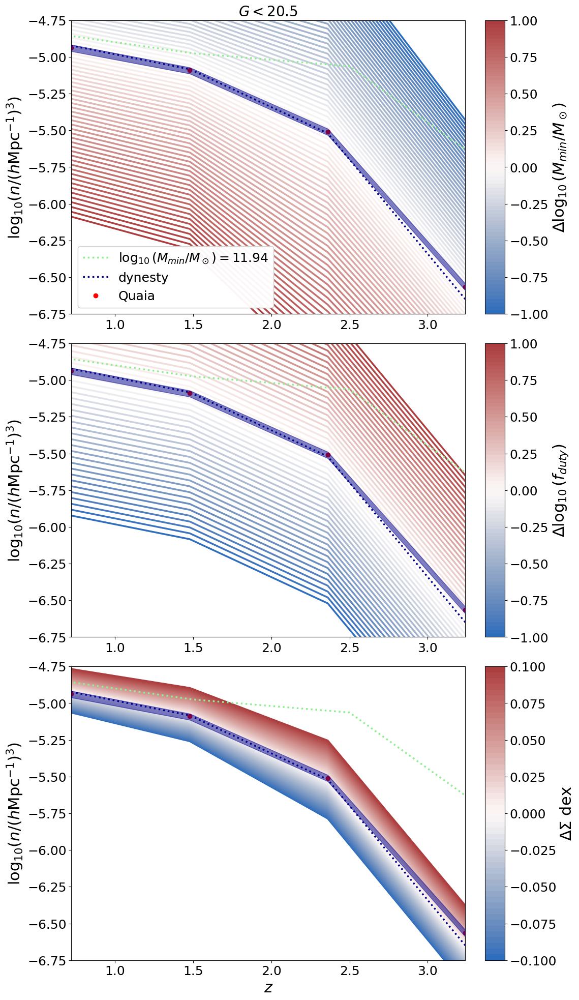

In [99]:
fig = plt.figure(figsize = (11, 24))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(3, 3, width_ratios = [1, 0.05, 0.05], wspace = 0, hspace = 0.1)
ax1 = fig.add_subplot(gs[0])
ylim = -6.75, -4.75

for k in range(len(bins)):
        
    n_q_theory=[M(bins, HOD_scatter(10**f_duty[j], M_min[j]-1+k/int(len(bins)/2), bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]
    ax1.plot(zbin, np.log10(n_q_theory), linewidth = 2.5, #alpha = (1+k)/len(bins),
             label = r'$f_{{duty}}: {:.2f}\%-{:.2f}\%, M_{{min}}:[{:.2f}-{:.2f}] M_\odot$'.format(f_duty[0]*100, f_duty[-1]*100, np.log10(bins[0]), 
                                                                                                  np.log10(bins[-1])), color = cmap_M_min[k])

n_q_theory=[M(bins_M_min[j], n_m_array[j], a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]
n_q_theory_fit=[M(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]

ax1.plot(z_eff, np.log10(n_q_theory), linewidth = 2.5, color = 'lightgreen', linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.plot(zbin, np.log10(n_q_theory_fit), linewidth = 2.5, color = 'darkblue', linestyle = ':', label = r'$\chi^2$ minimization') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, np.log10(n_q_theory_fit_lo), np.log10(n_q_theory_fit_hi), color = 'darkblue', alpha = 0.5, label = r'$\chi^2$ minimization', zorder = 3) # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.errorbar(zbin, np.log10(n_q), linewidth = 2.5, marker = 'o', label = 'Quaia', color = 'red',
             yerr = [np.log10(n_q)-np.log10(np.subtract(n_q, n_q_err)), np.log10(np.add(n_q, n_q_err))-np.log10(n_q)], linestyle = 'None')

ax1.set_title('$G<{}$'.format(G_hi))
ax1.set_xlim(zbin[0], zbin[-1])

custom_lines = [Line2D([0], [0], color = 'lightgreen', linestyle = ':', linewidth = 2.5, 
                       label = r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0])),
                Line2D([0], [0], color = 'darkblue', linestyle = ':', linewidth = 2.5, 
                       label = 'dynesty'), 
                Line2D([0], [0], color = 'red', marker = 'o', linestyle = 'None', linewidth = 2.5, label = 'Quaia')]
second_legend = ax1.legend(handles = custom_lines)
fig.add_artist(second_legend)

ax1.set_ylabel(r'log$_{10}(n/(h\mathrm{Mpc}^{-1})^3)$')
ax1.set_ylim(ylim)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[0,-1]), 
                    label = '$\Delta \log_{10}(M_{min}/M_\odot)$')

ax1 = fig.add_subplot(gs[3])
i = 1
l = 38

for k in range(len(fduty_array)):
        
    n_q_theory=[M(bins, HOD_scatter(10**(f_duty[j]-1+k/int(len(fduty_array)/2)), M_min[j], bins, sigma[j]), a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]

    ax1.plot(zbin, np.log10(n_q_theory), linewidth = 2.5, #alpha = (1+k)/len(bins),
             color = cmap_fduty_k[k])
    
n_q_theory = [M(bins_M_min[j], n_m_array[j], a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]
ax1.plot(z_eff, np.log10(n_q_theory), linewidth = 2.5, color = 'lightgreen', linestyle = ':', 
         label = r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0])) # color = cmaps[i][j], alpha = (l+1)/len(bins)) np.log10(bins[l])

ax1.plot(zbin, np.log10(n_q_theory_fit), linewidth = 2.5, color = 'darkblue', linestyle = ':', label = r'dynesty') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, np.log10(n_q_theory_fit_lo), np.log10(n_q_theory_fit_hi), color = 'darkblue', alpha = 0.5, zorder = 3) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.errorbar(zbin, np.log10(n_q), linewidth = 2.5, marker = 'o', label = 'Quaia', color = 'red',
             yerr = [np.log10(n_q)-np.log10(np.subtract(n_q, n_q_err)), np.log10(np.add(n_q, n_q_err))-np.log10(n_q)], linestyle = 'None')

ax1.set_ylabel(r'log$_{10}(n/(h\mathrm{Mpc}^{-1})^3)$')
ax1.set_ylim(ylim)
ax1.set_xlim(zbin[0], zbin[-1])

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[1,-1]), 
                    label = '$\Delta \log_{10}(f_{duty})$')

ax1 = fig.add_subplot(gs[6])
for k in range(len(sigma_k_array)):
        
    n_q_theory=[M(bins, HOD_scatter(10**f_duty[j], M_min[j], bins, sigma[j]+delta*(-1+k/int(len(sigma_k_array)/2))), a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]
    ax1.plot(zbin, np.log10(n_q_theory), linewidth = 2.5, #alpha = (1+k)/len(bins),
             color = cmap_sigma[k])
    
n_q_theory = [M(bins_M_min[j], n_m_array[j], a = a_zbin[j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]
ax1.plot(z_eff, np.log10(n_q_theory), linewidth = 2.5, color = 'lightgreen', linestyle = ':', 
         label = r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0])) # color = cmaps[i][j], alpha = (l+1)/len(bins)) np.log10(bins[l])

ax1.plot(zbin, np.log10(n_q_theory_fit), linewidth = 2.5, color = 'darkblue', linestyle = ':', label = r'dynesty') # color = cmaps[i][j], alpha = (l+1)/len(bins))
ax1.fill_between(zbin, np.log10(n_q_theory_fit_lo), np.log10(n_q_theory_fit_hi), color = 'darkblue', alpha = 0.5, zorder = 3) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.errorbar(zbin, np.log10(n_q), linewidth = 2.5, marker = 'o', label = 'Quaia', color = 'red',
             yerr = [np.log10(n_q)-np.log10(np.subtract(n_q, n_q_err)), np.log10(np.add(n_q, n_q_err))-np.log10(n_q)], linestyle = 'None')

ax1.set_xlabel('$z$')
ax1.set_ylabel(r'log$_{10}(n/(h\mathrm{Mpc}^{-1})^3)$')
ax1.set_ylim(ylim)
ax1.set_xlim(zbin[0], zbin[-1])

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), cax = fig.add_subplot(gs[2,-1]), 
                    label = '$\Delta \Sigma$ dex')
plt.show()